# Task 1: Data Loading, Cleaning & Exploratory Data Analysis


## 1.1 Load and Inspect the Dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings
filterwarnings('ignore')

In [ ]:
df = pd.read_csv("/content/adult.csv.zip")

In [ ]:
df.shape

(48842, 15)

In [ ]:
df.dtypes

,0
age,int64
workclass,object
fnlwgt,int64
education,object
educational-num,int64
marital-status,object
occupation,object
relationship,object
race,object
gender,object


In [ ]:
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [ ]:
for col in df.select_dtypes(include="object"):
    df[col] = df[col].str.strip()

print("Whitespace stripping completed.")

Whitespace stripping completed.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


## 1.2 Handle Missing Values

In [ ]:
df.replace('?',np.nan,inplace=True)

df.isnull().sum()

,0
age,0
workclass,2799
fnlwgt,0
education,0
educational-num,0
marital-status,0
occupation,2809
relationship,0
race,0
gender,0


#1.3	Drop redundant columns	Drop

In [ ]:
df.dropna(inplace=True)

In [ ]:
df.shape

(45222, 15)

## 1.4 Encode the Target

In [ ]:
df['income'] = (df['income'] == '>50K').astype(int)

print(df['income'].value_counts())

income
0    34014
1    11208
Name: count, dtype: int64


In [ ]:
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,0
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,0
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,1
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,1
5,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,0


#1.5 Exploratory Visualisations

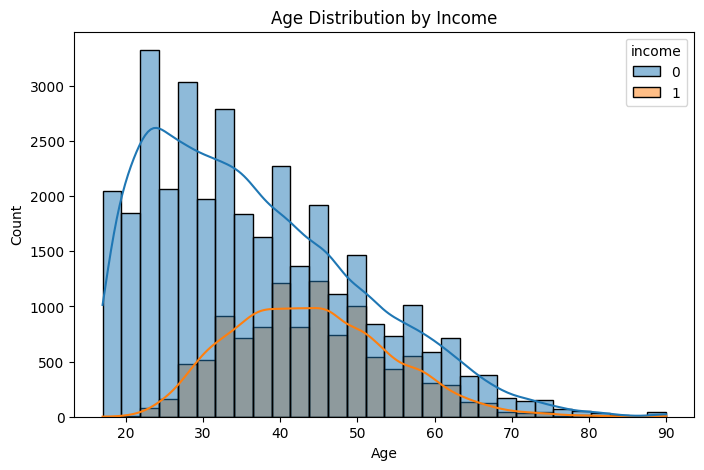

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(data=df,x='age',hue='income',kde=True,bins=30)
plt.title('Age Distribution by Income')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

### Observation — Age Distribution

The age distribution shows differences between the two income classes. Individuals with higher income generally tend to be more represented in the higher age ranges compared with the `<=50K` group.

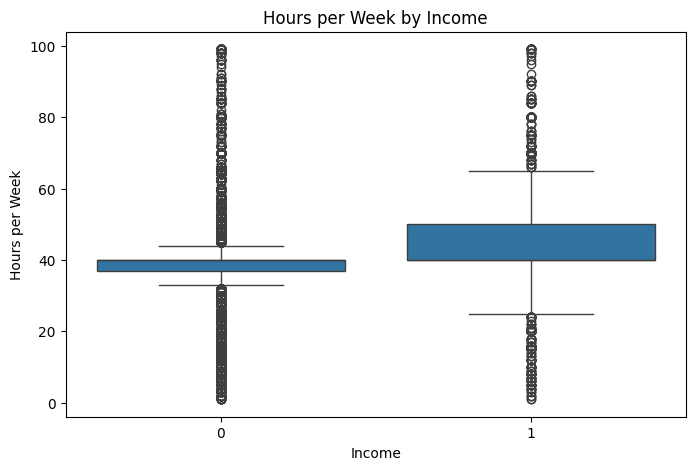

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x='income',y='hours-per-week')
plt.title('Hours per Week by Income')
plt.xlabel('Income')
plt.ylabel('Hours per Week')
plt.show()

### Observation — Hours per Week

The boxplot shows the distribution of weekly working hours across the two income classes. The `>50K` group generally shows higher working-hour patterns compared with the `<=50K` group.

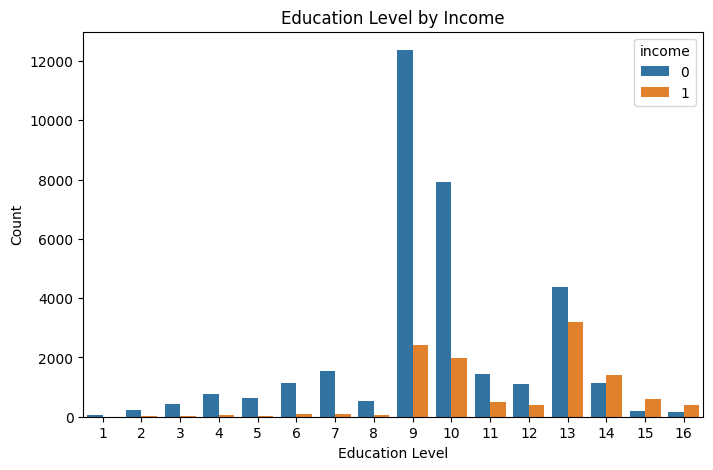

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,x='educational-num',hue='income')
plt.title('Education Level by Income')
plt.xlabel('Education Level')
plt.ylabel('Count')
plt.show()

### Observation — Education

The distribution indicates that higher `education.num` values are more strongly associated with the `>50K` income class. This suggests that education level is an important predictor of income.

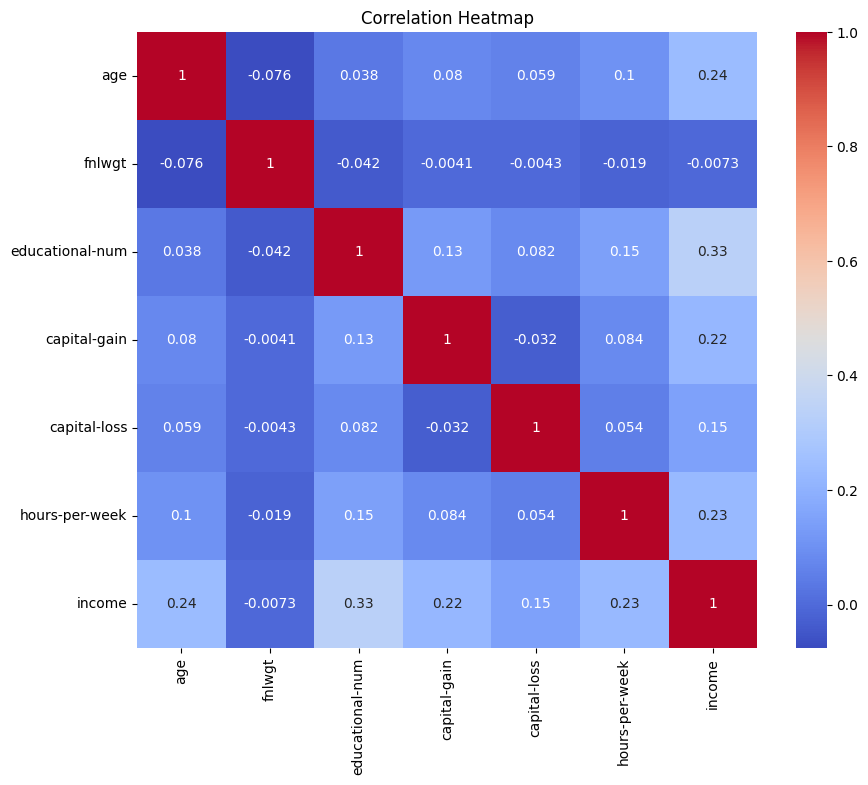

In [ ]:
plt.figure(figsize=(10,8))
numeric_df = df.select_dtypes(include=[np.number])
correlation = numeric_df.corr()
sns.heatmap(correlation,annot=True,cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

### Observation — Correlation Heatmap

The correlation heatmap shows the relationships between the numeric variables and the income target. Features with stronger correlation with `income` may provide more useful information for predicting whether an individual earns above or below $50K.

1.6 Encode Categoricals & Scale Numerics

In [ ]:
X = df.drop(['income'],axis=1)
y = df['income']

In [ ]:
print(X.shape)
print(y.shape)

(45222, 14)
(45222,)


In [ ]:
X = pd.get_dummies(X,drop_first=True)
print("shape after One-hot Encoding:",X.shape)
print("\n Data Type:")
print(X.dtypes.value_counts())

shape after One-hot Encoding: (45222, 96)

 Data Type:
bool     90
int64     6
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

numeric_columns = ['age','educational-num','hours-per-week']
scaler = StandardScaler()
X[numeric_columns] = scaler.fit_transform(X[numeric_columns])


In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Shape of X_train:",X_train.shape)
print("Shape of X_test:",X_test.shape)
print("Shape of y_train:",y_train.shape)
print("Shape of y_test:",y_test.shape)

Shape of X_train: (36177, 96)
Shape of X_test: (9045, 96)
Shape of y_train: (36177,)
Shape of y_test: (9045,)


In [ ]:
# Confirm class ratio in both splits

print("Overall Class Distribution:")
print(y.value_counts(normalize=True))

print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True))

Overall Class Distribution:
income
0    0.752156
1    0.247844
Name: proportion, dtype: float64

Training Class Distribution:
income
0    0.752163
1    0.247837
Name: proportion, dtype: float64

Testing Class Distribution:
income
0    0.752128
1    0.247872
Name: proportion, dtype: float64


### Observation

The categorical features were converted into binary columns using One-Hot Encoding with `drop_first=True`.

StandardScaler was applied only to the five numerical features: `age`, `education.num`, `capital.gain`, `capital.loss`, and `hours.per.week`. The One-Hot Encoded binary columns were not scaled.

The dataset was divided into 80% training and 20% testing data using stratified sampling, preserving the class distribution in both sets.

#Task 2: MLP Architecture — Baseline ANN:

2.1 Build the Baseline ANN

In [ ]:
import tensorflow as tf
from tensorflow import keras

In [ ]:
def built_ann(
    input_dim,
    hidden_units,
    activation,
    initalizer,
    use_batch_norm,
    optimizer,
    loss
):

  model = keras.Sequential()
  model.add(keras.layers.Dense(hidden_units,activation=activation,kernel_initializer=initalizer,input_dim=input_dim))

  if use_batch_norm:
    model.add(keras.layers.BatchNormalization())

  model.add(keras.layers.Dense(hidden_units[1],activation=activation,kernel_initializer=initalizer))

  if use_batch_norm:
    model.add(keras.layers.BatchNormalization())

  model.add(keras.layers.Dense(1,activation='sigmoid'))

  model.compile(optimizer=optimizer,loss=loss,metrics=['accuracy'])

  return model


2.2 Baseline ANN architecture

In [ ]:
import tensorflow as tf
from tensorflow import keras

def built_ann(
    input_dim,
    hidden_units,
    activation,
    initializer,
    use_batch_norm,
    optimizer,
    loss
):

  model = keras.Sequential()

  # First hidden layer
  model.add(keras.layers.Dense(hidden_units[0], activation=activation, kernel_initializer=initializer, input_dim=input_dim))
  if use_batch_norm:
    model.add(keras.layers.BatchNormalization())

  # Subsequent hidden layers
  for units in hidden_units[1:]:
    model.add(keras.layers.Dense(units, activation=activation, kernel_initializer=initializer))
    if use_batch_norm:
      model.add(keras.layers.BatchNormalization())

  # Output layer
  model.add(keras.layers.Dense(1,activation='sigmoid'))

  model.compile(optimizer=optimizer,loss=loss,metrics=['accuracy'])

  return model

model_base = built_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128,64],
    activation='relu',
    initializer='glorot_uniform',
    use_batch_norm=False,
    optimizer='adam',
    loss='binary_crossentropy'
)

model_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,737 (81.00 KB)

 Trainable params: 20,737 (81.00 KB)

 Non-trainable params: 0 (0.00 B)

### WHY Sigmoid for Binary Classification?

The output layer uses a single neuron with a sigmoid activation because this is a binary classification problem.

Sigmoid converts the output into a probability between 0 and 1, representing the probability that an individual belongs to the `>50K` income class. A single sigmoid output is therefore sufficient instead of using a two-neuron softmax output.

### WHY MLP for Tabular Data?

A Multi-Layer Perceptron is appropriate for the Adult Income dataset because the dataset contains structured demographic and employment features such as age, education, occupation, working hours, and capital gains.

The MLP can learn nonlinear relationships between these numerical and encoded categorical features to predict whether income is above or below $50K.

2.3 Train the Baseline ANN

In [ ]:
history_base = model_base.fit(X_train,y_train,epochs=50,batch_size=64,validation_split=0.1,verbose=1)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6691 - loss: 281.7594 - val_accuracy: 0.7819 - val_loss: 77.1693
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6742 - loss: 235.5547 - val_accuracy: 0.7825 - val_loss: 135.7136
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6782 - loss: 169.8360 - val_accuracy: 0.7731 - val_loss: 52.0186
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6828 - loss: 161.9870 - val_accuracy: 0.2474 - val_loss: 453.6681
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6782 - loss: 170.7705 - val_accuracy: 0.7722 - val_loss: 56.8951
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6853 - loss: 111.0553 - val_accuracy: 0.7756 - val_loss: 42.3674
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6876 - loss: 90.0003 - val_accuracy: 0.7764 - val_loss: 28.9965
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6874 - loss: 102

### Observation

The baseline ANN was trained for 50 epochs using a batch size of 32 and 10% of the training data as the validation set.

The training history stored in `history_base` will be used to visualize the training and validation loss and accuracy in the next step.

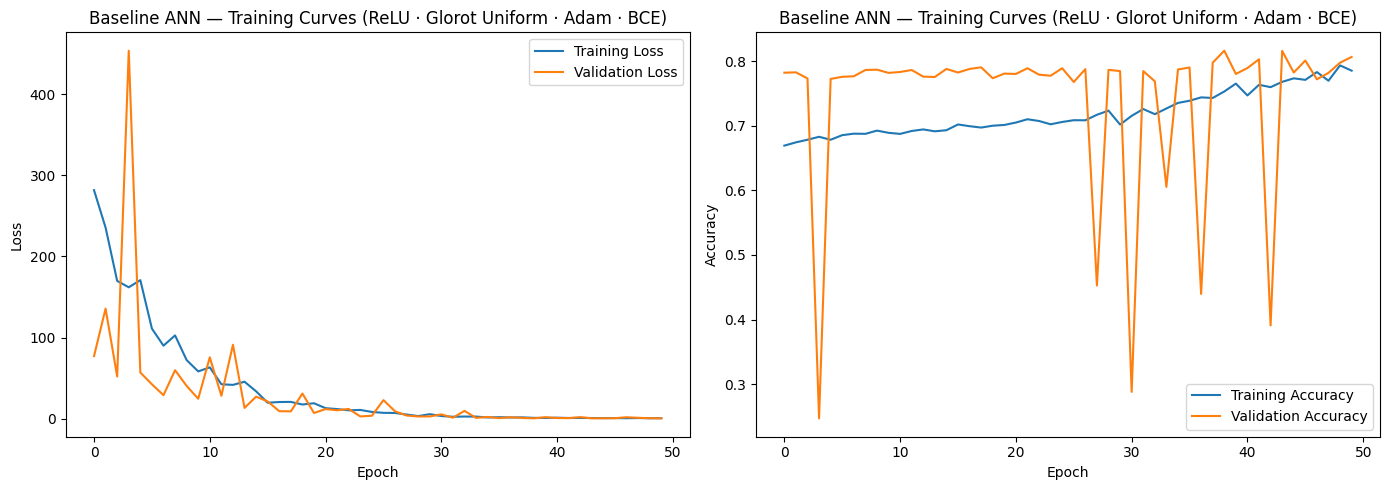

In [ ]:
plt.figure(figsize=(14, 5))

# Loss
plt.subplot(1, 2, 1)

plt.plot(history_base.history["loss"],label="Training Loss")

plt.plot(history_base.history["val_loss"],label="Validation Loss")

plt.title("Baseline ANN — Training Curves (ReLU · Glorot Uniform · Adam · BCE)")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()


# Accuracy
plt.subplot(1, 2, 2)

plt.plot(history_base.history["accuracy"],label="Training Accuracy")

plt.plot(history_base.history["val_accuracy"],label="Validation Accuracy")

plt.title("Baseline ANN — Training Curves (ReLU · Glorot Uniform · Adam · BCE)")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

#2.4 Evaluate Baseline ANN

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
y_pred_prob = model_base.predict(X_test).flatten()
y_pred = (y_pred_prob > 0.5).astype(int)

print("Classification Report")

print(classification_report(y_test,y_pred))

283/283 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Classification Report
              precision    recall  f1-score   support

           0       0.81      0.97      0.88      6803
           1       0.80      0.31      0.45      2242

    accuracy                           0.81      9045
   macro avg       0.80      0.64      0.67      9045
weighted avg       0.81      0.81      0.78      9045



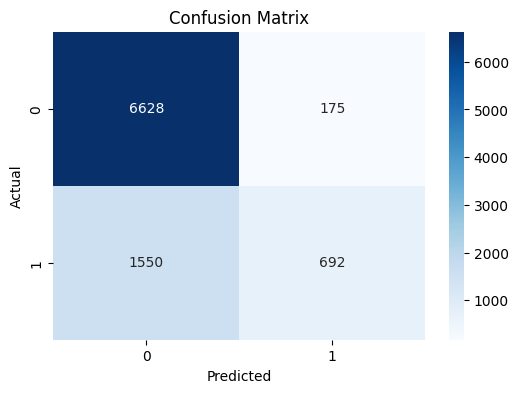

In [ ]:
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Observation

The classification report provides Precision, Recall, F1-score, and Accuracy for both income classes.

The confusion matrix shows the number of correct and incorrect predictions made by the baseline ANN for each income class.

## 2.5 Baseline ANN — Model Performance

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate performance metrics

accuracy_base = accuracy_score(y_test, y_pred)
precision_base = precision_score(y_test, y_pred)
recall_base = recall_score(y_test, y_pred)
f1_base = f1_score(y_test, y_pred)

print(f"Baseline ANN Accuracy : {accuracy_base:.4f}")
print(f"Baseline ANN Precision: {precision_base:.4f}")
print(f"Baseline ANN Recall   : {recall_base:.4f}")
print(f"Baseline ANN F1-Score : {f1_base:.4f}")

Baseline ANN Accuracy : 0.8093
Baseline ANN Precision: 0.7982
Baseline ANN Recall   : 0.3087
Baseline ANN F1-Score : 0.4452


#Task 3: Activation Functions — Comparison Experiment

# 3.1 Train 4 Models with Different Hidden Activations

In [ ]:
model_relu = built_ann(
    input_dim = X_train.shape[1],
    hidden_units = [128,64],
    activation = 'relu',
    initializer = 'glorot_uniform',
    use_batch_norm = False,
    optimizer = keras.optimizers.Adam(),
    loss = 'binary_crossentropy'
)

history_relu = model_relu.fit(
    X_train,
    y_train,
    epochs = 50,
    batch_size = 64,
    validation_split = 0.1,
    verbose = 1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6686 - loss: 233.0506 - val_accuracy: 0.7676 - val_loss: 31.1810
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6757 - loss: 158.5333 - val_accuracy: 0.2490 - val_loss: 66.0066
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6761 - loss: 143.2564 - val_accuracy: 0.7855 - val_loss: 128.3670
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6780 - loss: 121.6966 - val_accuracy: 0.2499 - val_loss: 81.0019
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6812 - loss: 99.0864 - val_accuracy: 0.2499 - val_loss: 82.2872
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6805 - loss: 101.8631 - val_accuracy: 0.2512 - val_loss: 80.2538
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6836 - loss: 96.8276 - val_accuracy: 0.7601 - val_loss: 215.2129
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6840 - loss: 92.4

In [ ]:
model_tanh = built_ann(
    input_dim = X_train.shape[1],
    hidden_units = [128,64],
    activation = 'tanh',
    initializer = 'glorot_uniform',
    use_batch_norm = False,
    optimizer = keras.optimizers.Adam(),
    loss = 'binary_crossentropy'
)

history_tanh = model_tanh.fit(
    X_train,
    y_train,
    epochs = 50,
    batch_size = 64,
    validation_split = 0.1,
    verbose = 1
)


Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7611 - loss: 0.5508 - val_accuracy: 0.7615 - val_loss: 0.5483
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7642 - loss: 0.5435 - val_accuracy: 0.7753 - val_loss: 0.5365
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7607 - loss: 0.5514 - val_accuracy: 0.7587 - val_loss: 0.5516
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7576 - loss: 0.5531 - val_accuracy: 0.7612 - val_loss: 0.5534
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7590 - loss: 0.5522 - val_accuracy: 0.7587 - val_loss: 0.5496
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7590 - loss: 0.5522 - val_accuracy: 0.7612 - val_loss: 0.5518
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7594 - loss: 0.5523 - val_accuracy: 0.7612 - val_loss: 0.5526
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7598 - loss: 0.5516 - val_accuracy: 0.

In [ ]:
# Sigmoid hidden-layer model

model_sigmoid = built_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="sigmoid",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer=keras.optimizers.Adam(),
    loss="binary_crossentropy"
)

history_sigmoid = model_sigmoid.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7584 - loss: 0.5491 - val_accuracy: 0.7615 - val_loss: 0.5484
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7598 - loss: 0.5521 - val_accuracy: 0.7620 - val_loss: 0.5475
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7632 - loss: 0.5469 - val_accuracy: 0.7756 - val_loss: 0.5352
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7686 - loss: 0.5383 - val_accuracy: 0.7676 - val_loss: 0.5410
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7708 - loss: 0.5385 - val_accuracy: 0.7676 - val_loss: 0.5433
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7680 - loss: 0.5430 - val_accuracy: 0.7670 - val_loss: 0.5428
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7683 - loss: 0.5415 - val_accuracy: 0.7814 - val_loss: 0.5321
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7659 - loss: 0.5452 - val_accuracy: 0.

In [ ]:
# ELU model

model_elu = built_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="elu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer=keras.optimizers.Adam(),
    loss="binary_crossentropy"
)

history_elu = model_elu.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6746 - loss: 195.1056 - val_accuracy: 0.2474 - val_loss: 379.1385
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6777 - loss: 159.3644 - val_accuracy: 0.7814 - val_loss: 61.5703
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6817 - loss: 133.7142 - val_accuracy: 0.6446 - val_loss: 23.9652
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6875 - loss: 83.0863 - val_accuracy: 0.7850 - val_loss: 28.2910
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6844 - loss: 93.8188 - val_accuracy: 0.7720 - val_loss: 33.8066
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6866 - loss: 73.5293 - val_accuracy: 0.7651 - val_loss: 33.9141
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6909 - loss: 56.1294 - val_accuracy: 0.7778 - val_loss: 52.3350
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6981 - loss: 52.5222

### Observation

Four ANN models were trained using ReLU, Tanh, Sigmoid, and ELU hidden activations. Each model was trained for 50 epochs with a batch size of 64 and a validation split of 0.1.

3.2 Activation Comparison — 4-Panel Plot

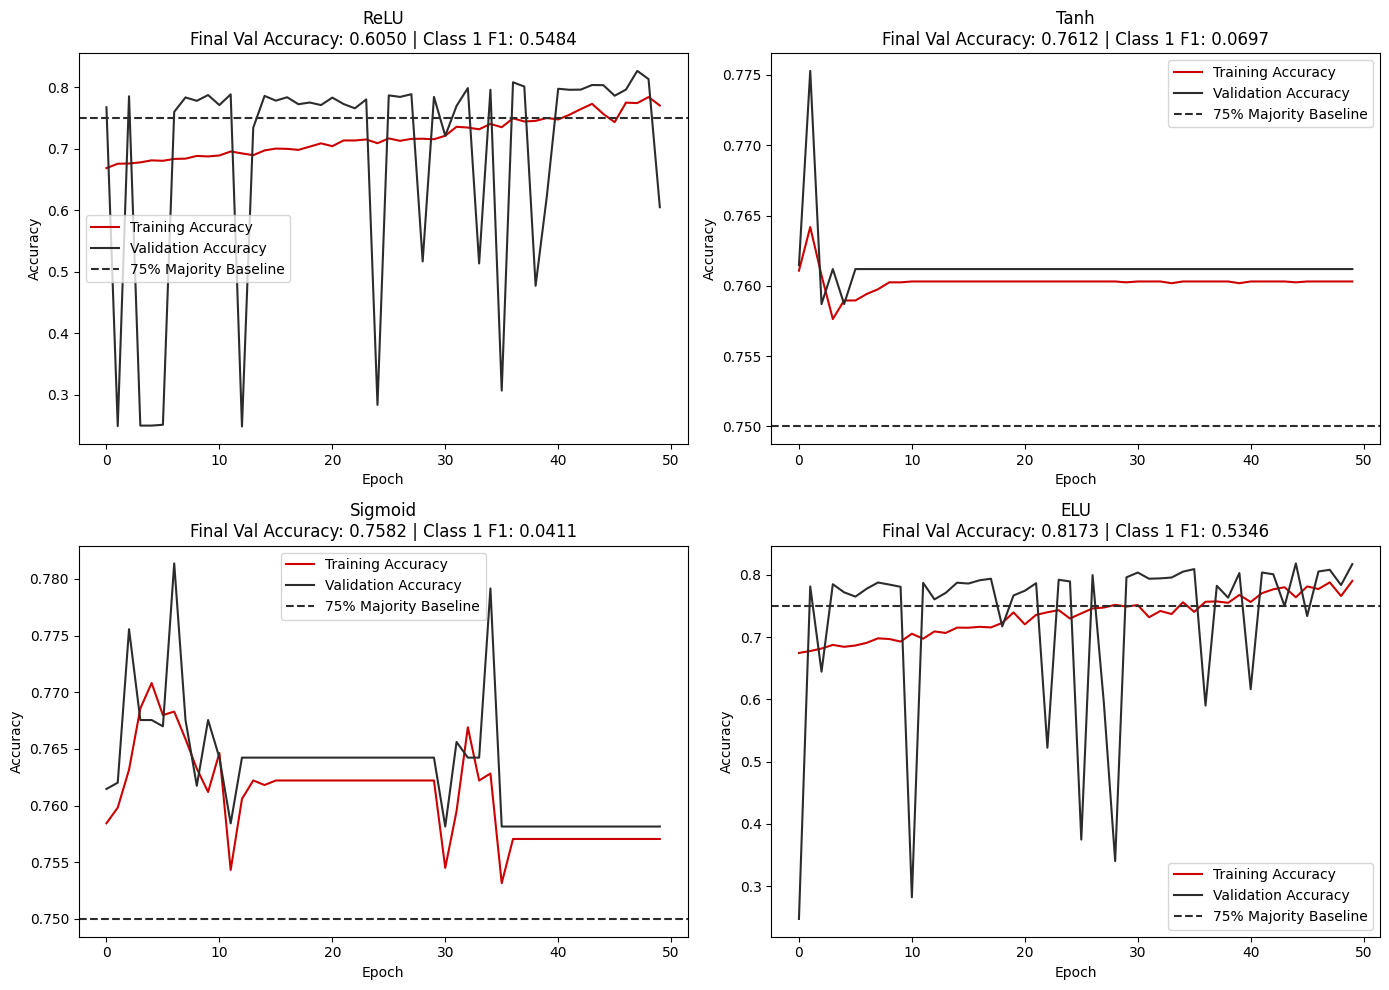

In [ ]:


# Store models and histories
activation_results = {
    "ReLU": (model_relu, history_relu),
    "Tanh": (model_tanh, history_tanh),
    "Sigmoid": (model_sigmoid, history_sigmoid),
    "ELU": (model_elu, history_elu)
}

plt.figure(figsize=(14, 10))

for i, (activation, (model, history)) in enumerate(activation_results.items(), 1):

    # Predictions
    y_pred_prob = model.predict(X_test, verbose=0).flatten()
    y_pred = (y_pred_prob >= 0.5).astype(int)

    # Final validation accuracy
    final_val_accuracy = history.history["val_accuracy"][-1]

    # F1-score for class 1 (>50K)
    f1_class_1 = f1_score(y_test, y_pred, pos_label=1)

    # Subplot
    plt.subplot(2, 2, i)

    # Training accuracy
    plt.plot(
        history.history["accuracy"],
        color="#CC0000",
        label="Training Accuracy"
    )

    # Validation accuracy
    plt.plot(
        history.history["val_accuracy"],
        color="#2C2C2C",
        label="Validation Accuracy"
    )

    # 75% majority-class baseline
    plt.axhline(
        y=0.75,
        color="#2C2C2C",
        linestyle="--",
        label="75% Majority Baseline"
    )

    plt.title(
        f"{activation}\n"
        f"Final Val Accuracy: {final_val_accuracy:.4f} | "
        f"Class 1 F1: {f1_class_1:.4f}"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

plt.tight_layout()
plt.show()

### Observation

The four activation functions are compared using training and validation accuracy.

The horizontal dashed line represents the 75% naive majority-class baseline. The final validation accuracy and class-1 F1-score shown in each panel provide a direct comparison of the four activation functions.

# 3.3 Dead Neuron Check — ReLU

In [ ]:
intermediate = keras.Model(
    inputs=model_relu.inputs[0],
    outputs=model_relu.layers[0].output
)

activations = intermediate.predict(
    X_test[:500],
    verbose=0
)

# Calculate dead fraction
dead_fraction = np.mean(activations == 0)

print(f"Dead Fraction: {dead_fraction:.4f}")

Dead Fraction: 0.9355


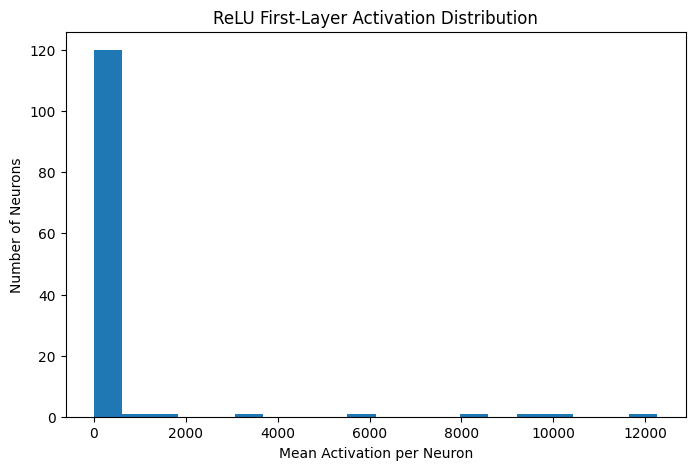

In [ ]:
# Mean activation per neuron

mean_activation_per_neuron = np.mean(
    activations,
    axis=0
)

# Plot distribution

plt.figure(figsize=(8, 5))

plt.hist(
    mean_activation_per_neuron,
    bins=20
)

plt.title("ReLU First-Layer Activation Distribution")
plt.xlabel("Mean Activation per Neuron")
plt.ylabel("Number of Neurons")

plt.show()

### Observation

The dead-neuron fraction for the ReLU first hidden layer is:

**Dead Fraction = [record the value printed above]**

A dead ReLU neuron produces an output of zero for inputs that remain on the negative side of the activation function, which can prevent useful gradient updates.

ELU helps avoid dead neurons by allowing small negative outputs for negative inputs:

**ELU(x) = α(eˣ − 1), for x < 0**

This keeps a non-zero gradient path for negative inputs and can help neurons continue learning.

# 3.4 Gradient Flow Check — Sigmoid Hidden Layers

In [ ]:
# Gradient flow check for sigmoid hidden layers

loss_fn = keras.losses.BinaryCrossentropy()

# Take a single batch
X_batch = X_train[:64]
y_batch = y_train.iloc[:64].values

with tf.GradientTape() as tape:

    # Explicitly convert X_batch to a float32 NumPy array
    y_pred = model_sigmoid(X_batch.values.astype(np.float32), training=True)

    loss = loss_fn(y_batch, y_pred)

gradients = tape.gradient(
    loss,
    model_sigmoid.trainable_weights
)

# Collect IDs of kernel variables from Dense layers
kernel_var_ids = {id(layer.kernel) for layer in model_sigmoid.layers if isinstance(layer, keras.layers.Dense)}

# Extract gradients corresponding to Dense layers
dense_gradients = []

for i, var in enumerate(model_sigmoid.trainable_weights):
    if id(var) in kernel_var_ids:
        gradient = gradients[i]
        mean_gradient = tf.reduce_mean(
            tf.abs(gradient)
        ).numpy()
        dense_gradients.append(mean_gradient)

print("Mean Absolute Gradient by Dense Layer:")

for i, gradient in enumerate(dense_gradients, 1):
    print(f"Layer {i}: {gradient:.8f}")

Mean Absolute Gradient by Dense Layer:
Layer 1: 0.00000000
Layer 2: 0.00003657
Layer 3: 0.01170534


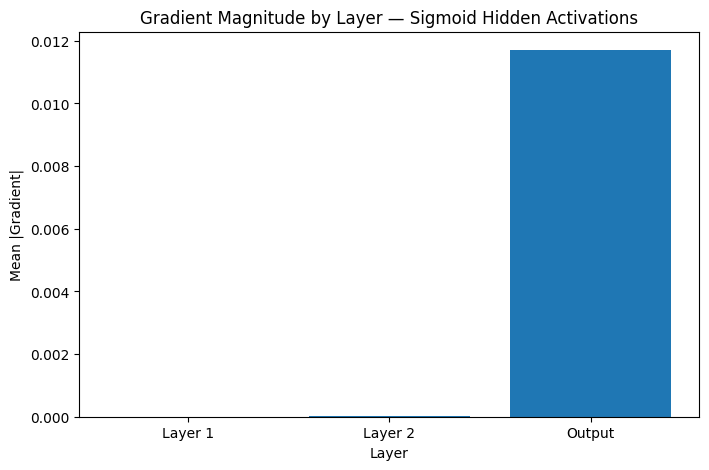

In [ ]:
# Plot mean absolute gradient by layer

layer_names = [
    "Layer 1",
    "Layer 2",
    "Output"
]

plt.figure(figsize=(8, 5))

plt.bar(
    layer_names,
    dense_gradients
)

plt.title(
    "Gradient Magnitude by Layer — Sigmoid Hidden Activations"
)

plt.xlabel("Layer")
plt.ylabel("Mean |Gradient|")

plt.show()

### Observation

If the Layer 1 gradients are orders of magnitude smaller than the Output layer gradients, vanishing gradients are occurring.

This happens because the derivative of the sigmoid function is:

**σ'(x) = σ(x)(1 − σ(x)) ≤ 0.25**

When gradients are multiplied across multiple sigmoid layers, their magnitude can shrink exponentially. As a result, earlier layers receive very small gradients and learn slowly.

# 3.5 Activation Summary

## Activation Function Comparison

| Activation | Formula | Output Range | Zero-Centred | Vanishing Gradient Risk | Dead Neuron Risk | Val Accuracy on Adult (this run) |
|---|---|---|---|---|---|---|
| ReLU | max(0, x) | [0, ∞) | No | Low | Yes | Record from 3.2 |
| Tanh | tanh(x) | (-1, 1) | Yes | Medium | No | Record from 3.2 |
| Sigmoid (hidden) | 1 / (1 + e⁻ˣ) | (0, 1) | No | High | No | Record from 3.2 |
| ELU | x if x > 0, α(eˣ − 1) if x ≤ 0 | (-α, ∞) | Approximately | Low | No | Record from 3.2 |
| Sigmoid (output layer only) | 1 / (1 + e⁻ˣ) | (0, 1) | No | Not applicable | No | Output layer |

### Recommendation

For this dataset, **ReLU or ELU** is recommended for the hidden layers because they provide better gradient flow than sigmoid and avoid the strong vanishing-gradient problem observed with sigmoid hidden layers.

The final choice should be based on the validation accuracy and class-1 F1-score observed in this run.

Sigmoid in the **output layer** is always appropriate for this binary classification problem, regardless of which activation function is used in the hidden layers.

#Task 4: Weight Initialization Techniques

4.1 Train 5 Models with Different Initialisers

In [ ]:
model_glorot_uniform = built_ann(
    input_dim = X_train.shape[1],
    hidden_units = [128,64],
    activation = "relu",
    initializer = "glorot_uniform",
    use_batch_norm = False,
    optimizer = keras.optimizers.Adam(),
    loss = "binary_crossentropy"
)


history_glorot_uniform = model_glorot_uniform.fit(
    X_train,
    y_train,
    epochs = 50,
    batch_size = 32,
    validation_split = 0.1,
    verbose = 1
)

Epoch 1/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6712 - loss: 348.7001 - val_accuracy: 0.7692 - val_loss: 53.7826
Epoch 2/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.6762 - loss: 205.4893 - val_accuracy: 0.7747 - val_loss: 71.4542
Epoch 3/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6815 - loss: 183.9330 - val_accuracy: 0.7844 - val_loss: 181.9037
Epoch 4/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6810 - loss: 128.2776 - val_accuracy: 0.7662 - val_loss: 20.7554
Epoch 5/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6856 - loss: 105.1418 - val_accuracy: 0.2582 - val_loss: 71.4146
Epoch 6/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6864 - loss: 73.9564 - val_accuracy: 0.2631 - val_loss: 49.1524
Epoch 7/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6924 - loss: 51.2342 - val_accuracy: 0.2908 - val_loss: 26.8262
Epoch 8/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.69

In [ ]:
model_glorot_normal = built_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="glorot_normal",
    use_batch_norm=False,
    optimizer=keras.optimizers.Adam(),
    loss="binary_crossentropy"
)

history_glorot_normal = model_glorot_normal.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6766 - loss: 304.4044 - val_accuracy: 0.7861 - val_loss: 201.2902
Epoch 2/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6751 - loss: 205.1679 - val_accuracy: 0.7822 - val_loss: 266.6325
Epoch 3/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6811 - loss: 155.9665 - val_accuracy: 0.7839 - val_loss: 88.1477
Epoch 4/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6821 - loss: 151.4109 - val_accuracy: 0.7844 - val_loss: 67.2394
Epoch 5/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6871 - loss: 90.8494 - val_accuracy: 0.7816 - val_loss: 95.4486
Epoch 6/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6894 - loss: 74.4356 - val_accuracy: 0.2767 - val_loss: 46.8638
Epoch 7/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6916 - loss: 55.0670 - val_accuracy: 0.7830 - val_loss: 70.2045
Epoch 8/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.70

In [ ]:
# He Uniform

model_he_uniform = built_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_uniform",
    use_batch_norm=False,
    optimizer=keras.optimizers.Adam(),
    loss="binary_crossentropy"
)

history_he_uniform = model_he_uniform.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6732 - loss: 345.6614 - val_accuracy: 0.2474 - val_loss: 475.8726
Epoch 2/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6749 - loss: 249.3753 - val_accuracy: 0.7595 - val_loss: 656.1777
Epoch 3/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6847 - loss: 178.8211 - val_accuracy: 0.7692 - val_loss: 30.5639
Epoch 4/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6837 - loss: 153.5698 - val_accuracy: 0.7786 - val_loss: 55.1434
Epoch 5/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6835 - loss: 112.9743 - val_accuracy: 0.7866 - val_loss: 100.8958
Epoch 6/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6889 - loss: 90.3229 - val_accuracy: 0.2501 - val_loss: 135.1925
Epoch 7/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6886 - loss: 56.5963 - val_accuracy: 0.2642 - val_loss: 50.7633
Epoch 8/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0

In [ ]:
# He Normal

model_he_normal = built_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer=keras.optimizers.Adam(),
    loss="binary_crossentropy"
)

history_he_normal = model_he_normal.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6700 - loss: 465.8389 - val_accuracy: 0.2474 - val_loss: 376.9157
Epoch 2/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6820 - loss: 358.4308 - val_accuracy: 0.7687 - val_loss: 778.7651
Epoch 3/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6827 - loss: 249.7993 - val_accuracy: 0.7833 - val_loss: 307.1043
Epoch 4/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6776 - loss: 224.6397 - val_accuracy: 0.2537 - val_loss: 147.5529
Epoch 5/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6814 - loss: 191.7992 - val_accuracy: 0.7852 - val_loss: 181.3925
Epoch 6/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.6864 - loss: 141.4164 - val_accuracy: 0.7722 - val_loss: 55.1533
Epoch 7/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6881 - loss: 132.3343 - val_accuracy: 0.7750 - val_loss: 37.4161
Epoch 8/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy

In [ ]:
# Zeros

model_zeros = built_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="zeros",
    use_batch_norm=False,
    optimizer=keras.optimizers.Adam(),
    loss="binary_crossentropy"
)

history_zeros = model_zeros.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7521 - loss: 0.6174 - val_accuracy: 0.7526 - val_loss: 0.5746
Epoch 2/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7521 - loss: 0.5651 - val_accuracy: 0.7526 - val_loss: 0.5602
Epoch 3/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7521 - loss: 0.5603 - val_accuracy: 0.7526 - val_loss: 0.5595
Epoch 4/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7521 - loss: 0.5600 - val_accuracy: 0.7526 - val_loss: 0.5594
Epoch 5/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7521 - loss: 0.5600 - val_accuracy: 0.7526 - val_loss: 0.5595
Epoch 6/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7521 - loss: 0.5600 - val_accuracy: 0.7526 - val_loss: 0.5594
Epoch 7/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7521 - loss: 0.5600 - val_accuracy: 0.7526 - val_loss: 0.5595
Epoch 8/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7521 - loss: 0.5600 - 

### Observation

Five ReLU-based ANN models were trained using Glorot Uniform, Glorot Normal, He Uniform, He Normal, and Zeros initialisation techniques for 50 epochs.

## 4.2 WHY Initialisation Matters

Neural networks trained with all-zero weights suffer from the **symmetry problem** — every neuron in a layer produces the same output, receives the same gradient, and updates to the same value.

The network collapses to a single effective neuron per layer regardless of width.

**Xavier/Glorot initialisation** draws weights from a distribution with:

**Var = 2 / (fan_in + fan_out)**

This is calibrated to keep the variance of activations and gradients stable across tanh/sigmoid layers.

**He initialisation** uses:

**Var = 2 / fan_in**

The extra factor of 2 compensates for ReLU zeroing out half of all activations on average, maintaining the effective variance for ReLU networks.

## 4.3 Convergence Speed Comparison Plot

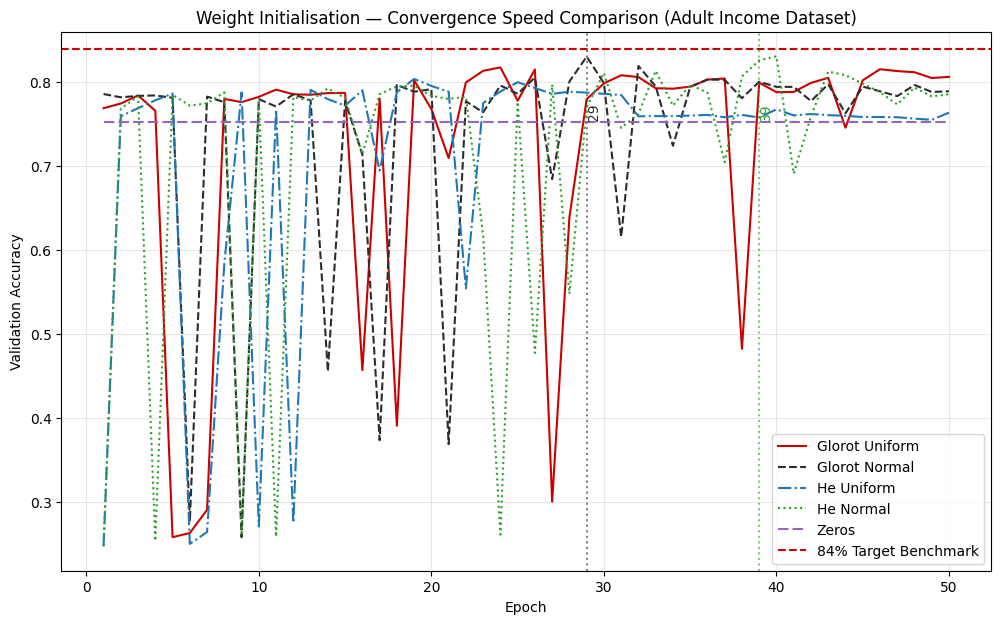

In [ ]:
# Validation accuracy for all 5 initialisers

initialization_histories = {
    "Glorot Uniform": history_glorot_uniform,
    "Glorot Normal": history_glorot_normal,
    "He Uniform": history_he_uniform,
    "He Normal": history_he_normal,
    "Zeros": history_zeros
}

plt.figure(figsize=(12, 7))

linestyles = {
    "Glorot Uniform": "-",
    "Glorot Normal": "--",
    "He Uniform": "-.",
    "He Normal": ":",
    "Zeros": (0, (5, 2))
}

colors = {
    "Glorot Uniform": "#CC0000",
    "Glorot Normal": "#2C2C2C",
    "He Uniform": "#1f77b4",
    "He Normal": "#2ca02c",
    "Zeros": "#9467bd"
}

for name, history in initialization_histories.items():

    val_accuracy = history.history["val_accuracy"]

    plt.plot(
        range(1, len(val_accuracy) + 1),
        val_accuracy,
        label=name,
        linestyle=linestyles[name],
        color=colors[name]
    )

    # Find first epoch crossing 82%
    if name != "Zeros":

        crossed = np.where(
            np.array(val_accuracy) >= 0.82
        )[0]

        if len(crossed) > 0:

            first_epoch = crossed[0] + 1

            plt.axvline(
                x=first_epoch,
                linestyle=":",
                alpha=0.6,
                color=colors[name]
            )

            plt.text(
                first_epoch,
                0.755,
                f"{first_epoch}",
                rotation=90,
                verticalalignment="bottom",
                color=colors[name]
            )

# 84% target benchmark
plt.axhline(
    y=0.84,
    color="#CC0000",
    linestyle="--",
    label="84% Target Benchmark"
)

plt.title(
    "Weight Initialisation — Convergence Speed Comparison (Adult Income Dataset)"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

### Observation

The convergence curves compare the five weight initialisation techniques.

The `Zeros` initialisation is expected to remain close to the majority-class baseline because all neurons start with identical weights and suffer from the symmetry problem.

The He initialisation variants are expected to converge fastest with ReLU because He initialisation is specifically designed to maintain suitable activation and gradient variance for ReLU networks.

The vertical tick lines indicate the first epoch at which each non-zero initialisation model crosses 82% validation accuracy.

## 4.4 Zeros Failure Demonstration

### Objective
Demonstrate the failure of zero weight initialization by comparing the training loss and validation accuracy of the zeros-initialised model.

### Expected Output
A plot showing the training loss and validation accuracy of the zeros-initialised model.

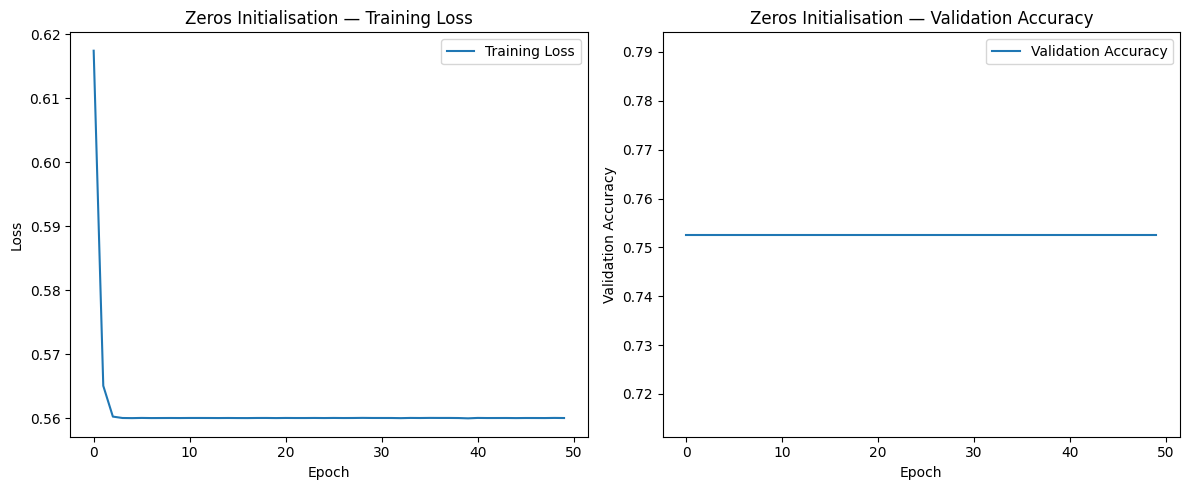

In [ ]:
# Zeros-initialised model failure demonstration

zeros_history = history_zeros.history

plt.figure(figsize=(12, 5))

# Training Loss
plt.subplot(1, 2, 1)

plt.plot(
    zeros_history["loss"],
    label="Training Loss"
)

plt.title("Zeros Initialisation — Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()


# Validation Accuracy
plt.subplot(1, 2, 2)

plt.plot(
    zeros_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Zeros Initialisation — Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

### Observation

The zeros-initialised model shows a nearly flat validation accuracy around **75%**, which corresponds approximately to the majority-class baseline.

This happens because the network outputs a constant prediction close to **0**, predicting the majority class for almost every sample.

The network never breaks symmetry because all neurons start with identical weights, produce identical outputs, receive identical gradients, and therefore update identically.

This is the clearest demonstration of why weight initialisation is not merely a detail in neural network training.

## 4.5 Weight Distribution Visualisation

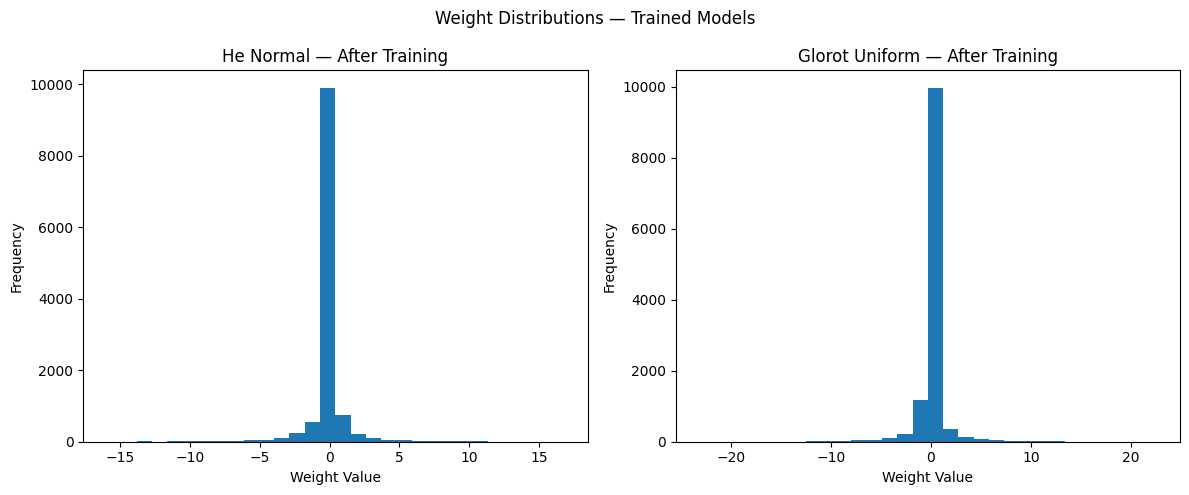

In [ ]:
# Extract trained weights from the first Dense layer

weights_he_normal_after = model_he_normal.layers[0].get_weights()[0].flatten()

weights_glorot_uniform_after = model_glorot_uniform.layers[0].get_weights()[0].flatten()


# Plot weight distributions

plt.figure(figsize=(12, 5)) # Adjusted figure size for 2 plots

# He Normal - After
plt.subplot(1, 2, 1)

plt.hist(
    weights_he_normal_after,
    bins=30
)

plt.title("He Normal — After Training")
plt.xlabel("Weight Value")
plt.ylabel("Frequency")


# Glorot Uniform - After
plt.subplot(1, 2, 2)

plt.hist(
    weights_glorot_uniform_after,
    bins=30
)

plt.title("Glorot Uniform — After Training")
plt.xlabel("Weight Value")
plt.ylabel("Frequency")


plt.suptitle("Weight Distributions — Trained Models")

plt.tight_layout()
plt.show()

### Observation

The initial weight distributions should closely match their theoretical shapes, with the Glorot distribution generally narrower and the He distribution wider.

After 50 epochs of training, both distributions should have spread and shifted as backpropagation updates the weights.

The initialiser only determines the starting point of the weights; training through backpropagation reshapes the weight distribution.

## Task 5: Loss Functions


5.1
Binary Cross-Entropy — the correct loss



In [ ]:
# Confirm the baseline ANN uses Binary Cross-Entropy

print("Baseline ANN Loss Function:")
print(model_base.loss)

Baseline ANN Loss Function:
binary_crossentropy


### Why Binary Cross-Entropy?

The Binary Cross-Entropy (BCE) loss is:

L = −[y·log(p) + (1−y)·log(1−p)]

where:

- `p` is the sigmoid output probability.
- `y` is the true label, either 0 or 1.

BCE directly penalises confident wrong predictions.

For example, when the true label is `y = 0` but the model predicts `p → 1`, the term `log(1−p) → −∞`, resulting in a very large loss.

Binary Cross-Entropy is also the negative log-likelihood of a Bernoulli distribution, making it the natural choice for binary classification.

# 5.2 MSE as Classification Loss — Wrong Tool Experiment

In [ ]:
# Build MSE model

model_mse = built_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer=keras.optimizers.Adam(),
    loss="mean_squared_error"
)

# Train MSE model

history_mse = model_mse.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7521 - loss: 0.2479 - val_accuracy: 0.7526 - val_loss: 0.2474
Epoch 2/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7521 - loss: 0.2479 - val_accuracy: 0.7526 - val_loss: 0.2474
Epoch 3/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7521 - loss: 0.2479 - val_accuracy: 0.7526 - val_loss: 0.2474
Epoch 4/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7521 - loss: 0.2479 - val_accuracy: 0.7526 - val_loss: 0.2474
Epoch 5/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7521 - loss: 0.2479 - val_accuracy: 0.7526 - val_loss: 0.2474
Epoch 6/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7521 - loss: 0.2479 - val_accuracy: 0.7526 - val_loss: 0.2474
Epoch 7/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7521 - loss: 0.2479 - val_accuracy: 0.7526 - val_loss: 0.2474
Epoch 8/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7521 - loss: 0.2479 - 

In [ ]:
# Build MSE model

model_mse = built_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer=keras.optimizers.Adam(),
    loss="mean_squared_error"
)

# Train MSE model

history_mse = model_mse.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.2479 - loss: 0.7521 - val_accuracy: 0.2474 - val_loss: 0.7526
Epoch 2/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2479 - loss: 0.7521 - val_accuracy: 0.2474 - val_loss: 0.7526
Epoch 3/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2479 - loss: 0.7521 - val_accuracy: 0.2474 - val_loss: 0.7526
Epoch 4/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2479 - loss: 0.7521 - val_accuracy: 0.2474 - val_loss: 0.7526
Epoch 5/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.2479 - loss: 0.7521 - val_accuracy: 0.2474 - val_loss: 0.7526
Epoch 6/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2479 - loss: 0.7521 - val_accuracy: 0.2474 - val_loss: 0.7526
Epoch 7/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2479 - loss: 0.7521 - val_accuracy: 0.2474 - val_loss: 0.7526
Epoch 8/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2479 - loss: 0.7521 - 

### Why MSE is a Wrong Tool for Classification

MSE treats the sigmoid output as a regression target and does not penalise confident wrong predictions as harshly as Binary Cross-Entropy.

For MSE with a sigmoid output, the gradient contains the term:

σ(x)(1−σ(x))

which can become very small when the sigmoid output saturates.

In contrast, the gradient of BCE with respect to the logit is:

p − y

which remains well-defined.

On imbalanced data such as Adult Income, this difference can be especially visible in the minority-class F1-score.

# 5.3 Weighted Binary Cross-Entropy — Handling Class Imbalance

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# Compute balanced class weights

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

class_weight_dict = {
    0: weights[0],
    1: weights[1]
}

print("Class Weights:")
print(class_weight_dict)

Class Weights:
{0: np.float64(0.6647495498144133), 1: np.float64(2.0174548293553425)}


In [ ]:
# Build Weighted BCE model

model_wbce = built_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer=keras.optimizers.Adam(),
    loss="binary_crossentropy"
)

In [ ]:
# Train Weighted BCE model

history_wbce = model_wbce.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5481 - loss: 535.8941 - val_accuracy: 0.2474 - val_loss: 594.3793
Epoch 2/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5566 - loss: 335.8544 - val_accuracy: 0.7814 - val_loss: 112.3003
Epoch 3/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5589 - loss: 248.2142 - val_accuracy: 0.2485 - val_loss: 176.3435
Epoch 4/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5650 - loss: 166.4298 - val_accuracy: 0.7653 - val_loss: 301.1439
Epoch 5/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5667 - loss: 151.8026 - val_accuracy: 0.2482 - val_loss: 227.7099
Epoch 6/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5731 - loss: 125.1246 - val_accuracy: 0.5218 - val_loss: 25.6756
Epoch 7/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5780 - loss: 103.3223 - val_accuracy: 0.2565 - val_loss: 115.5150
Epoch 8/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accurac

In [ ]:
# Predictions for baseline model

y_base_prob = model_base.predict(
    X_test,
    verbose=0
).flatten()

y_base_pred = (y_base_prob >= 0.5).astype(int)


# Predictions for weighted BCE model

y_wbce_prob = model_wbce.predict(
    X_test,
    verbose=0
).flatten()

y_wbce_pred = (y_wbce_prob >= 0.5).astype(int)

In [ ]:
# Class 1 metrics

precision_base = precision_score(
    y_test,
    y_base_pred,
    pos_label=1
)

recall_base = recall_score(
    y_test,
    y_base_pred,
    pos_label=1
)

f1_base = f1_score(
    y_test,
    y_base_pred,
    pos_label=1
)


precision_wbce = precision_score(
    y_test,
    y_wbce_pred,
    pos_label=1
)

recall_wbce = recall_score(
    y_test,
    y_wbce_pred,
    pos_label=1
)

f1_wbce = f1_score(
    y_test,
    y_wbce_pred,
    pos_label=1
)

print("Class 1 (>50K) Metrics")
print("-" * 40)

print(f"Baseline Precision : {precision_base:.4f}")
print(f"Baseline Recall    : {recall_base:.4f}")
print(f"Baseline F1-Score  : {f1_base:.4f}")

print()

print(f"WBCE Precision     : {precision_wbce:.4f}")
print(f"WBCE Recall        : {recall_wbce:.4f}")
print(f"WBCE F1-Score      : {f1_wbce:.4f}")

Class 1 (>50K) Metrics
----------------------------------------
Baseline Precision : 0.7982
Baseline Recall    : 0.3087
Baseline F1-Score  : 0.4452

WBCE Precision     : 0.9798
WBCE Recall        : 0.0433
WBCE F1-Score      : 0.0829


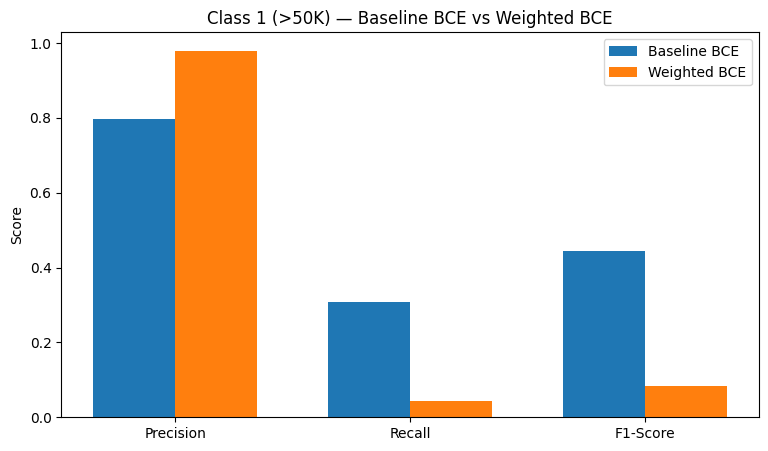

In [ ]:
# Compare class-1 Precision, Recall and F1

metrics = [
    "Precision",
    "Recall",
    "F1-Score"
]

baseline_values = [
    precision_base,
    recall_base,
    f1_base
]

wbce_values = [
    precision_wbce,
    recall_wbce,
    f1_wbce
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    baseline_values,
    width,
    label="Baseline BCE"
)

plt.bar(
    x + width / 2,
    wbce_values,
    width,
    label="Weighted BCE"
)

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Class 1 (>50K) — Baseline BCE vs Weighted BCE")
plt.legend()

plt.show()

### Observation

Weighted Binary Cross-Entropy penalises misclassification of minority-class samples more heavily.

For the `>50K` class, this can improve Recall by making the model more sensitive to minority-class samples, although Precision may decrease because more samples are classified as `>50K`.

This trade-off is important in income-targeting applications where missing a high-earner may be more costly than producing a false positive.

# 5.4 Focal Loss — Advanced Imbalance Handling

In [ ]:
# Focal Loss

def focal_loss(gamma=2.0, alpha=0.25):

    def loss(y_true, y_pred):

        y_pred = tf.clip_by_value(
            y_pred,
            1e-7,
            1 - 1e-7
        )

        bce = (
            -y_true * tf.math.log(y_pred)
            - (1 - y_true) * tf.math.log(1 - y_pred)
        )

        weight = (
            alpha * y_true * (1 - y_pred) ** gamma
            + (1 - alpha) * (1 - y_true) * y_pred ** gamma
        )

        return tf.reduce_mean(weight * bce)

    return loss

In [ ]:
# Build Focal Loss model

model_focal = built_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer=keras.optimizers.Adam(),
    loss=focal_loss(gamma=2.0, alpha=0.25)
)

In [ ]:
# Train Focal Loss model

history_focal = model_focal.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.2473 - loss: 8.9952 - val_accuracy: 0.2465 - val_loss: 9.0023
Epoch 2/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2473 - loss: 8.9952 - val_accuracy: 0.2465 - val_loss: 9.0023
Epoch 3/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.2473 - loss: 8.9952 - val_accuracy: 0.2465 - val_loss: 9.0023
Epoch 4/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2473 - loss: 8.9952 - val_accuracy: 0.2465 - val_loss: 9.0023
Epoch 5/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2473 - loss: 8.9952 - val_accuracy: 0.2465 - val_loss: 9.0023
Epoch 6/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2473 - loss: 8.9952 - val_accuracy: 0.2465 - val_loss: 9.0023
Epoch 7/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2473 - loss: 8.9952 - val_accuracy: 0.2465 - val_loss: 9.0023
Epoch 8/50
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2473 - loss: 8.9952 - 

In [ ]:
# Predictions

y_focal_prob = model_focal.predict(
    X_test,
    verbose=0
).flatten()

y_focal_pred = (
    y_focal_prob >= 0.5
).astype(int)

In [ ]:
# Class 1 Recall and F1 comparison

recall_focal = recall_score(
    y_test,
    y_focal_pred,
    pos_label=1
)

f1_focal = f1_score(
    y_test,
    y_focal_pred,
    pos_label=1
)

print("Class 1 (>50K) Comparison")
print("-" * 45)

print(f"Baseline BCE   - Recall: {recall_base:.4f} | F1: {f1_base:.4f}")
print(f"Weighted BCE   - Recall: {recall_wbce:.4f} | F1: {f1_wbce:.4f}")
print(f"Focal Loss     - Recall: {recall_focal:.4f} | F1: {f1_focal:.4f}")

Class 1 (>50K) Comparison
---------------------------------------------
Baseline BCE   - Recall: 0.3087 | F1: 0.4452
Weighted BCE   - Recall: 0.0433 | F1: 0.0829
Focal Loss     - Recall: 0.9978 | F1: 0.3966


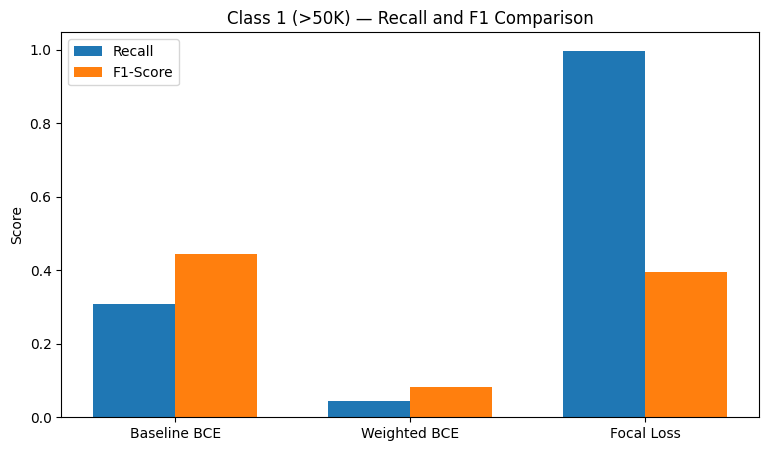

In [ ]:
# Compare Recall and F1-score

models = [
    "Baseline BCE",
    "Weighted BCE",
    "Focal Loss"
]

recall_values = [
    recall_base,
    recall_wbce,
    recall_focal
]

f1_values = [
    f1_base,
    f1_wbce,
    f1_focal
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    recall_values,
    width,
    label="Recall"
)

plt.bar(
    x + width / 2,
    f1_values,
    width,
    label="F1-Score"
)

plt.xticks(x, models)
plt.ylabel("Score")
plt.title("Class 1 (>50K) — Recall and F1 Comparison")
plt.legend()

plt.show()

### Observation

Focal Loss was introduced by Facebook AI (Lin et al., 2017) for object detection with extreme class imbalance.

The `(1−p)^γ` factor down-weights easy examples and focuses training on hard, misclassified examples.

With `γ = 2.0`, easy correctly classified examples contribute less to the loss, allowing the model to focus more on difficult examples.

The class-1 Recall and F1-score are compared with the baseline BCE and Weighted BCE models to evaluate its effectiveness on the imbalanced Adult Income dataset.

## 5.5 Loss Function Summary

### Loss Function Comparison

| Loss Function | Formula (Simplified) | Best For | Imbalance Handling | Class-1 F1 on Adult (this run) |
|---|---|---|---|---:|
| BCE | −[y·log(p) + (1−y)·log(1−p)] | Binary classification | No | Record from this run |
| Weighted BCE | Class-weighted BCE | Binary classification with class imbalance | Yes | Record from this run |
| MSE | (y−p)² | Regression | No | Record from this run |
| Focal Loss | Weighted BCE × focusing factor | Severe class imbalance / hard examples | Yes | Record from this run |

### Recommendation

For the Adult Income ANN, **Weighted Binary Cross-Entropy** is recommended when class imbalance is the main concern because it directly increases the penalty for misclassifying minority-class samples.

However, the final production choice should be based on the **Class-1 F1-score and Recall observed in this run**. Focal Loss is an advanced alternative when greater emphasis on difficult minority-class examples is required.

# Task 6: Batch Normalization

# 6.1 Build ANN with Batch Normalization

In [ ]:
# Build ANN with Batch Normalization

model_bn = keras.Sequential([

    keras.layers.Dense(
        128,
        kernel_initializer="he_normal",
        input_shape=(X_train.shape[1],)
    ),

    keras.layers.BatchNormalization(),

    keras.layers.Activation("relu"),

    keras.layers.Dense(
        64,
        kernel_initializer="he_normal"
    ),

    keras.layers.BatchNormalization(),

    keras.layers.Activation("relu"),

    keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

model_bn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_bn.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_42 (Dense)                │ (None, 128)            │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,505 (84.00 KB)

 Trainable params: 21,121 (82.50 KB)

 Non-trainable params: 384 (1.50 KB)

### Batch Normalization Parameters

Each BatchNormalization layer adds 4 parameters per neuron:

- **Gamma (γ)** — trainable scale parameter
- **Beta (β)** — trainable shift parameter
- **Moving Mean** — non-trainable running statistic
- **Moving Variance** — non-trainable running statistic

Therefore, each BatchNormalization layer adds:

**4 × number of neurons**

parameters.

Only **γ and β are trainable**. Moving mean and moving variance are non-trainable statistics accumulated during training.

## 6.2 WHY Batch Normalization

During training, as the weights of each layer update, the distribution of that layer's inputs (the outputs of the previous layer) shifts.

This forces every downstream layer to constantly re-adapt to a moving target — called **Internal Covariate Shift** (Ioffe & Szegedy, 2015).

Batch Normalization addresses this by normalising the pre-activation values within each mini-batch to zero mean and unit variance, then applying learnable scale (γ) and shift (β):

**BN(x) = γ · ((x − μ_B) / √(σ²_B + ε)) + β**

At inference, Batch Normalization uses running statistics (exponential moving averages of batch μ and σ²) accumulated during training — not the current batch.

### Benefits for Tabular Data

- Faster convergence
- Reduced sensitivity to learning rate
- Mild regularisation effect because batch statistics add noise

# 6.3 Train and Compare: With vs Without Batch Normalization

In [ ]:
# Train Batch Normalization model

history_bn = model_bn.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.7879 - loss: 0.5104 - val_accuracy: 0.7891 - val_loss: 0.5115
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7929 - loss: 0.5014 - val_accuracy: 0.7789 - val_loss: 0.5801
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7955 - loss: 0.4988 - val_accuracy: 0.6711 - val_loss: 0.6174
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7943 - loss: 0.4976 - val_accuracy: 0.7957 - val_loss: 0.5031
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7961 - loss: 0.4970 - val_accuracy: 0.7888 - val_loss: 0.5238
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7968 - loss: 0.4954 - val_accuracy: 0.7924 - val_loss: 0.5126
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7968 - loss: 0.4945 - val_accuracy: 0.7797 - val_loss: 0.5730
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7956 - loss: 0.4923 - val_accuracy: 0.

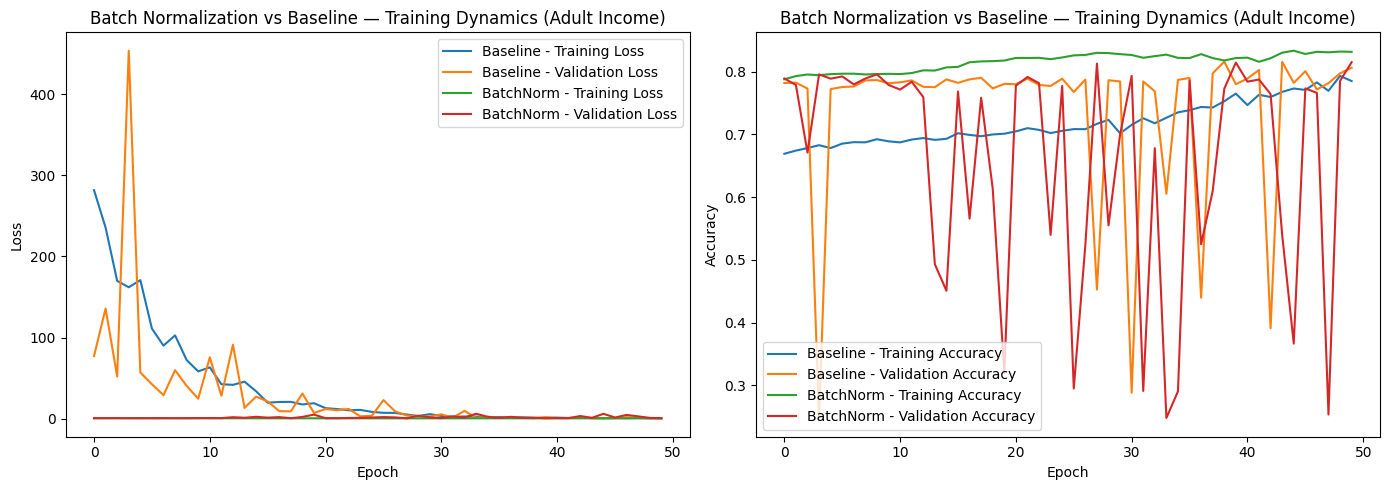

In [ ]:
# Compare training dynamics

plt.figure(figsize=(14, 5))

# Loss
plt.subplot(1, 2, 1)

plt.plot(
    history_base.history["loss"],
    label="Baseline - Training Loss"
)

plt.plot(
    history_base.history["val_loss"],
    label="Baseline - Validation Loss"
)

plt.plot(
    history_bn.history["loss"],
    label="BatchNorm - Training Loss"
)

plt.plot(
    history_bn.history["val_loss"],
    label="BatchNorm - Validation Loss"
)

plt.title(
    "Batch Normalization vs Baseline — Training Dynamics (Adult Income)"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()


# Accuracy
plt.subplot(1, 2, 2)

plt.plot(
    history_base.history["accuracy"],
    label="Baseline - Training Accuracy"
)

plt.plot(
    history_base.history["val_accuracy"],
    label="Baseline - Validation Accuracy"
)

plt.plot(
    history_bn.history["accuracy"],
    label="BatchNorm - Training Accuracy"
)

plt.plot(
    history_bn.history["val_accuracy"],
    label="BatchNorm - Validation Accuracy"
)

plt.title(
    "Batch Normalization vs Baseline — Training Dynamics (Adult Income)"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Evaluate Baseline ANN

y_base_prob = model_base.predict(
    X_test,
    verbose=0
).flatten()

y_base_pred = (y_base_prob >= 0.5).astype(int)

accuracy_base_bn = accuracy_score(
    y_test,
    y_base_pred
)

f1_base_bn = f1_score(
    y_test,
    y_base_pred,
    pos_label=1
)


# Evaluate Batch Normalization model

y_bn_prob = model_bn.predict(
    X_test,
    verbose=0
).flatten()

y_bn_pred = (y_bn_prob >= 0.5).astype(int)

accuracy_bn = accuracy_score(
    y_test,
    y_bn_pred
)

f1_bn = f1_score(
    y_test,
    y_bn_pred,
    pos_label=1
)


print("Test Performance")
print("-" * 40)

print(f"Baseline ANN      Accuracy: {accuracy_base_bn:.4f}")
print(f"Baseline ANN      F1:       {f1_base_bn:.4f}")

print()

print(f"BatchNorm ANN     Accuracy: {accuracy_bn:.4f}")
print(f"BatchNorm ANN     F1:       {f1_bn:.4f}")

Test Performance
----------------------------------------
Baseline ANN      Accuracy: 0.8093
Baseline ANN      F1:       0.4452

BatchNorm ANN     Accuracy: 0.8169
BatchNorm ANN     F1:       0.5403


### Observation

The Batch Normalization model is compared with the baseline ANN using training and validation loss and accuracy.

The comparison focuses on whether Batch Normalization produces a tighter train–validation gap and faster convergence.

Test Accuracy and class-1 F1-score are also reported for both models.

## 6.4 BatchNorm Position Experiment

In [ ]:
# BatchNorm AFTER activation
# Dense → ReLU → BatchNorm

model_bn_after = keras.Sequential([

    keras.layers.Dense(
        128,
        kernel_initializer="he_normal",
        input_shape=(X_train.shape[1],)
    ),

    keras.layers.Activation("relu"),

    keras.layers.BatchNormalization(),

    keras.layers.Dense(
        64,
        kernel_initializer="he_normal"
    ),

    keras.layers.Activation("relu"),

    keras.layers.BatchNormalization(),

    keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

model_bn_after.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
# Train BatchNorm AFTER activation

history_bn_after = model_bn_after.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.7835 - loss: 0.5151 - val_accuracy: 0.7830 - val_loss: 0.5516
Epoch 2/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7944 - loss: 0.4984 - val_accuracy: 0.7905 - val_loss: 0.4998
Epoch 3/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7947 - loss: 0.4974 - val_accuracy: 0.7875 - val_loss: 0.5569
Epoch 4/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7957 - loss: 0.4951 - val_accuracy: 0.2474 - val_loss: 1.0807
Epoch 5/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7946 - loss: 0.4956 - val_accuracy: 0.7850 - val_loss: 0.5203
Epoch 6/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7961 - loss: 0.4944 - val_accuracy: 0.6739 - val_loss: 0.6750
Epoch 7/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7943 - loss: 0.4911 - val_accuracy: 0.7781 - val_loss: 0.6151
Epoch 8/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7937 - loss: 0.4908 - val_accuracy: 0.

In [ ]:
# Train BatchNorm BEFORE activation

# Define model_bn_before with Batch Normalization BEFORE activation
model_bn_before = keras.Sequential([

    keras.layers.Dense(
        128,
        kernel_initializer="he_normal",
        input_shape=(X_train.shape[1],)
    ),

    keras.layers.BatchNormalization(),

    keras.layers.Activation("relu"),

    keras.layers.Dense(
        64,
        kernel_initializer="he_normal"
    ),

    keras.layers.BatchNormalization(),

    keras.layers.Activation("relu"),

    keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

model_bn_before.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_bn_before = model_bn_before.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.7789 - loss: 0.5185 - val_accuracy: 0.6694 - val_loss: 0.6442
Epoch 2/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7923 - loss: 0.5013 - val_accuracy: 0.7877 - val_loss: 0.5286
Epoch 3/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7935 - loss: 0.4999 - val_accuracy: 0.7944 - val_loss: 0.5054
Epoch 4/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7951 - loss: 0.4982 - val_accuracy: 0.7758 - val_loss: 0.5286
Epoch 5/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7957 - loss: 0.4968 - val_accuracy: 0.6376 - val_loss: 0.6271
Epoch 6/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7968 - loss: 0.4956 - val_accuracy: 0.7424 - val_loss: 0.5977
Epoch 7/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7956 - loss: 0.4943 - val_accuracy: 0.7894 - val_loss: 0.5689
Epoch 8/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7952 - loss: 0.4897 - val_accuracy: 0.

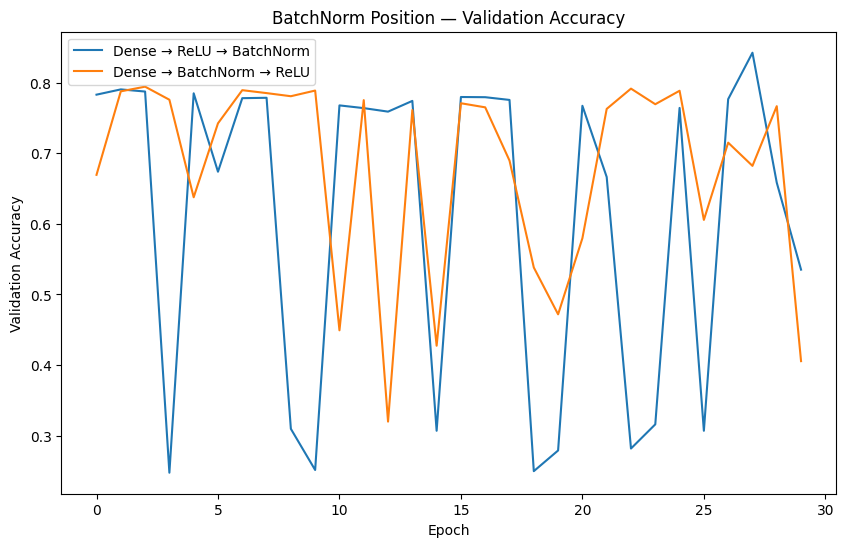

In [ ]:
# Compare validation accuracy

plt.figure(figsize=(10, 6))

plt.plot(
    history_bn_after.history["val_accuracy"],
    label="Dense → ReLU → BatchNorm"
)

plt.plot(
    history_bn_before.history["val_accuracy"],
    label="Dense → BatchNorm → ReLU"
)

plt.title("BatchNorm Position — Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()

plt.show()

### Observation

The two BatchNorm ordering strategies are compared using validation accuracy.

The original BatchNorm paper places normalization before the activation:

**Dense → BatchNorm → ReLU**

However, the alternative ordering:

**Dense → ReLU → BatchNorm**

can perform comparably or better on some datasets.

For the Adult Income dataset, the better ordering should be determined from the validation accuracy curves.

The difference should be considered statistically meaningful only if it is consistently large enough to exceed normal variation across training runs.

## 6.5 Inspect Learned Gamma and Beta

In [ ]:
# Retrieve learned BatchNormalization parameters

bn_layer = model_bn.layers[1]

gamma, beta, running_mean, running_var = bn_layer.get_weights()

print("Gamma shape:", gamma.shape)
print("Beta shape:", beta.shape)
print("Running Mean shape:", running_mean.shape)
print("Running Variance shape:", running_var.shape)

Gamma shape: (128,)
Beta shape: (128,)
Running Mean shape: (128,)
Running Variance shape: (128,)


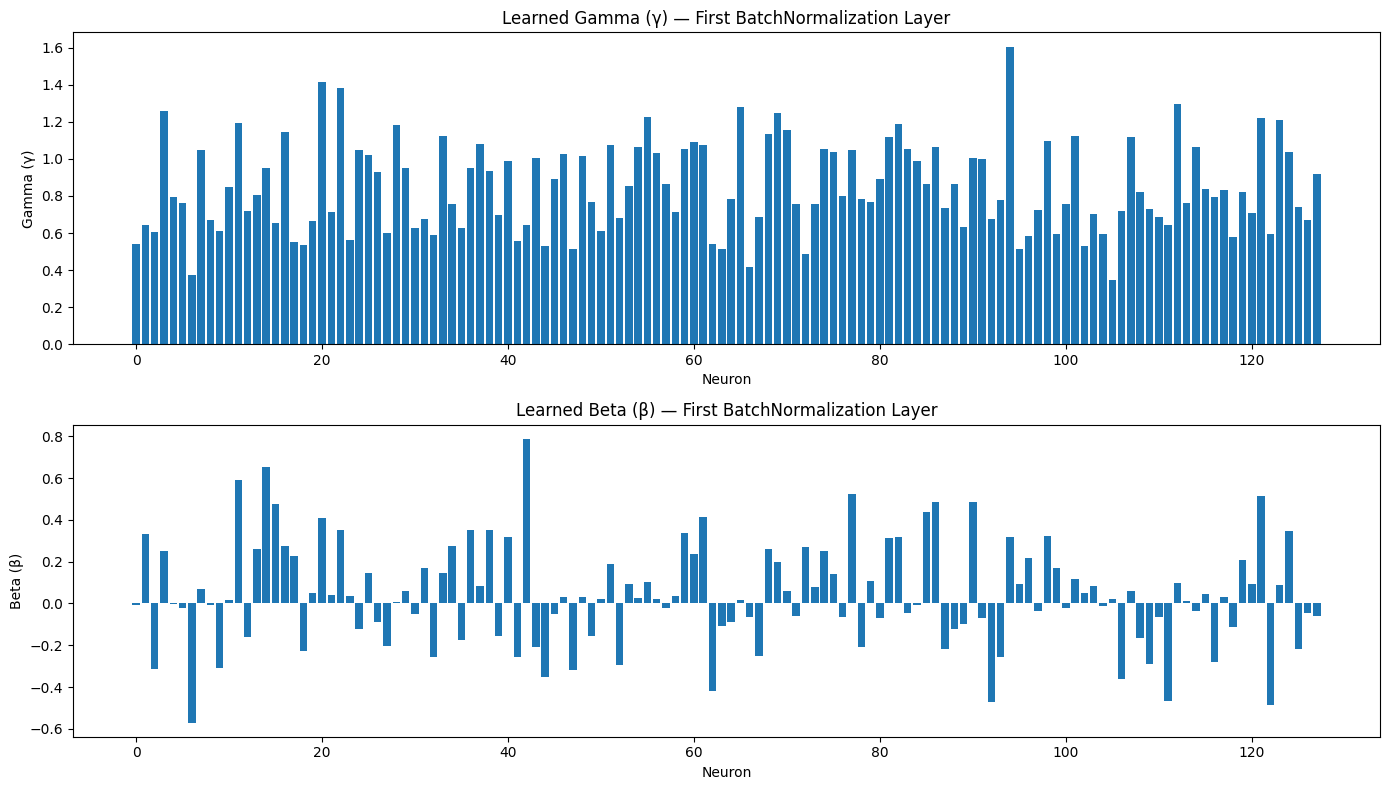

In [ ]:
# Plot gamma and beta values

plt.figure(figsize=(14, 8))

# Gamma
plt.subplot(2, 1, 1)

plt.bar(
    range(128),
    gamma
)

plt.title("Learned Gamma (γ) — First BatchNormalization Layer")
plt.xlabel("Neuron")
plt.ylabel("Gamma (γ)")


# Beta
plt.subplot(2, 1, 2)

plt.bar(
    range(128),
    beta
)

plt.title("Learned Beta (β) — First BatchNormalization Layer")
plt.xlabel("Neuron")
plt.ylabel("Beta (β)")

plt.tight_layout()
plt.show()

### Observation

The BatchNormalization layer learns a separate `gamma (γ)` and `beta (β)` for each of the 128 neurons.

Neurons where `|gamma|` is close to zero have been effectively gated off because their normalized activation contributes very little to the next layer. This suggests that the network learned their pre-activation distribution has low predictive value for income classification.

Neurons with large `|gamma|` values represent stronger internal signals learned by the model.

#Task 7: Optimizers — Convergence & Final Comparison

7.1 Build 5 Models with Different Optimisers

In [ ]:
# Optimizers

optimizers = {
    "SGD": "sgd",

    "SGD + Momentum": keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),

    "RMSprop": "rmsprop",

    "Adam": "adam",

    "Adam Explicit": keras.optimizers.Adam(
        learning_rate=0.001,
        beta_1=0.9,
        beta_2=0.999
    )
}

In [ ]:
# Build and train 5 optimizer models

optimizer_models = {}
optimizer_histories = {}

for name, optimizer in optimizers.items():

    model = built_ann(
        input_dim=X_train.shape[1],
        hidden_units=[128, 64],
        activation="relu",
        initializer="he_normal",
        use_batch_norm=True,
        optimizer=optimizer,
        loss="binary_crossentropy"
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=1
    )

    optimizer_models[name] = model
    optimizer_histories[name] = history

    print(f"{name} training completed.")

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7595 - loss: 0.5512 - val_accuracy: 0.7739 - val_loss: 0.5769
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7888 - loss: 0.5152 - val_accuracy: 0.7485 - val_loss: 0.5701
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7882 - loss: 0.5128 - val_accuracy: 0.6001 - val_loss: 0.6368
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7892 - loss: 0.5098 - val_accuracy: 0.7902 - val_loss: 0.5253
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7888 - loss: 0.5130 - val_accuracy: 0.7861 - val_loss: 0.5391
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7882 - loss: 0.5116 - val_accuracy: 0.7739 - val_loss: 0.7124
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7888 - loss: 0.5108 - val_accuracy: 0.7200 - val_loss: 0.5894
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7888 - loss: 0.5084 - val_accuracy: 0.

In [ ]:
# Verify that all five models and histories are stored

print("Models:")
print(list(optimizer_models.keys()))

print("\nHistories:")
print(list(optimizer_histories.keys()))

Models:
['SGD', 'SGD + Momentum', 'RMSprop', 'Adam', 'Adam Explicit']

Histories:
['SGD', 'SGD + Momentum', 'RMSprop', 'Adam', 'Adam Explicit']


### Observation

Five models were trained using the strongest configuration discovered so far:

- ReLU activation
- He Normal initialization
- Batch Normalization
- Binary Cross-Entropy loss
- 50 epochs
- Batch size = 64
- Validation split = 0.1

Only the optimizer was varied between the five experiments.

7.2 Optimiser Convergence Plot

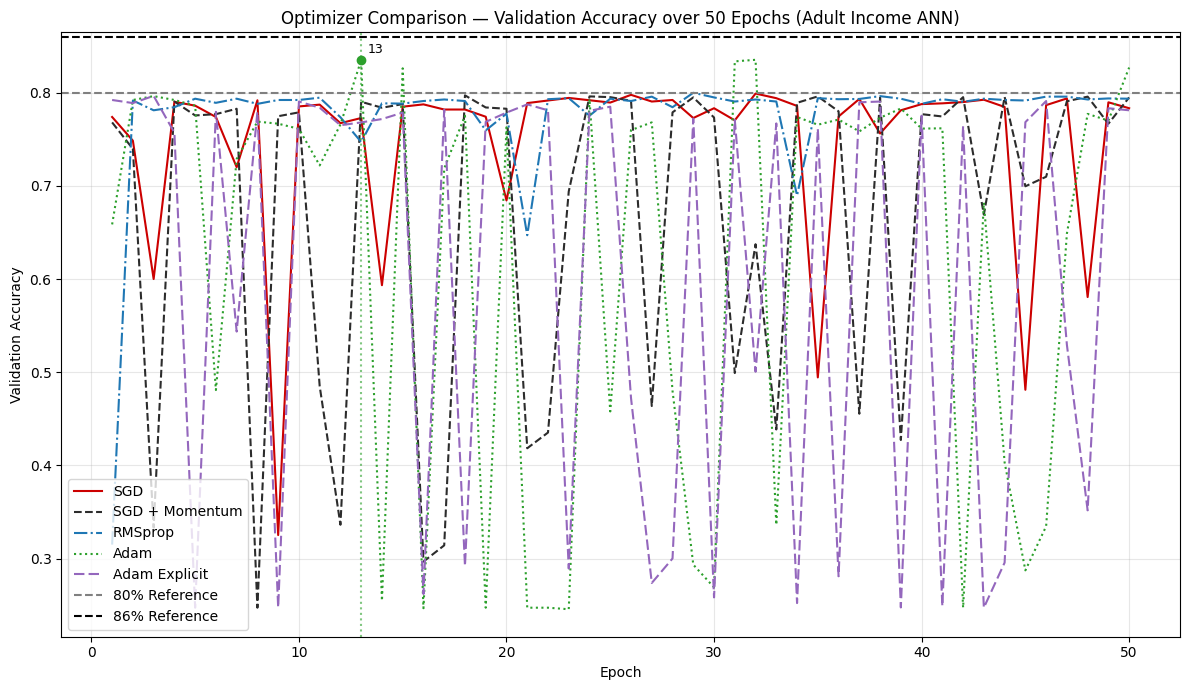

In [ ]:
# Optimizer convergence comparison

plt.figure(figsize=(12, 7))

linestyles = {
    "SGD": "-",
    "SGD + Momentum": "--",
    "RMSprop": "-.",
    "Adam": ":",
    "Adam Explicit": (0, (5, 2))
}

colors = {
    "SGD": "#CC0000",
    "SGD + Momentum": "#2C2C2C",
    "RMSprop": "#1f77b4",
    "Adam": "#2ca02c",
    "Adam Explicit": "#9467bd"
}

for name, history in optimizer_histories.items():

    val_accuracy = np.array(
        history.history["val_accuracy"]
    )

    epochs = np.arange(1, len(val_accuracy) + 1)

    # Validation accuracy curve
    plt.plot(
        epochs,
        val_accuracy,
        label=name,
        color=colors[name],
        linestyle=linestyles[name]
    )

    # Find first epoch crossing 83%
    crossed = np.where(val_accuracy >= 0.83)[0]

    if len(crossed) > 0:

        first_epoch = crossed[0] + 1
        first_accuracy = val_accuracy[crossed[0]]

        # Vertical marker
        plt.axvline(
            x=first_epoch,
            color=colors[name],
            linestyle=":",
            alpha=0.6
        )

        # Mark the crossing point
        plt.scatter(
            first_epoch,
            first_accuracy,
            color=colors[name],
            zorder=5
        )

        plt.annotate(
            f"{first_epoch}",
            xy=(first_epoch, first_accuracy),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9
        )

# 80% reference line
plt.axhline(
    y=0.80,
    color="gray",
    linestyle="--",
    label="80% Reference"
)

# 86% reference line
plt.axhline(
    y=0.86,
    color="black",
    linestyle="--",
    label="86% Reference"
)

plt.title(
    "Optimizer Comparison — Validation Accuracy over 50 Epochs (Adult Income ANN)"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Observation

The validation accuracy curves show the convergence behaviour of the five optimisers.

The vertical markers indicate the first epoch at which each optimiser reaches 83% validation accuracy.

The 80% and 86% horizontal reference lines provide benchmarks for comparing convergence and final validation performance.

## 7.3 WHY Adam Dominates

### 1. Vanilla SGD

Vanilla SGD uses a fixed global learning rate for all parameters.

It can converge slowly on sparse, high-dimensional One-Hot Encoded (OHE) features like the Adult Income dataset because it does not adapt the learning rate separately for different parameters.

---

### 2. SGD + Momentum

SGD with Momentum adds a velocity term:

**v = β·v + lr·∇L**

Momentum smooths oscillations and helps the optimizer move faster through flat regions of the loss surface.

However, it still uses the same learning rate for all parameters.

---

### 3. RMSprop

RMSprop divides the learning rate by a running average of squared gradients for each parameter:

**lr / √E[g²]**

This allows the optimizer to adapt to different gradient magnitudes and can work well for non-stationary signals.

---

### 4. Adam

Adam combines the advantages of Momentum and RMSprop.

It maintains:

- A first moment estimate `m` — similar to momentum
- A second moment estimate `v` — based on squared gradients

Adam also uses bias correction because `m` and `v` are initially set to zero.

The parameter update can be represented as:

**θ = θ − lr·m̂ / √(v̂ + ε)**

This adaptive per-parameter learning rate generally allows Adam to converge quickly and reliably.

---

### 5. Adam — Explicit Configuration

The explicit Adam configuration uses:

- `learning_rate = 0.001`
- `β₁ = 0.9`
- `β₂ = 0.999`

This confirms that the explicit configuration matches the Keras Adam defaults and the standard Adam configuration described by Kingma & Ba (2015).

---

### Results from This Run

After evaluating the five optimiser models, record:

- **Highest final class-1 F1-score:** `[optimizer name]`
- **Fastest convergence:** `[optimizer name]`

The optimiser reaching 83% validation accuracy at the earliest epoch can be considered the fastest according to the convergence experiment.

## 7.4 Learning Rate Sensitivity — SGD vs Adam

In [ ]:
# Learning rates

sgd_learning_rates = [0.0001, 0.001, 0.01, 0.1]
adam_learning_rates = [0.0001, 0.001, 0.01]

sgd_lr_histories = {}
adam_lr_histories = {}

In [ ]:
# Train SGD models with different learning rates

for lr in sgd_learning_rates:

    model = built_ann(
        input_dim=X_train.shape[1],
        hidden_units=[128, 64],
        activation="relu",
        initializer="he_normal",
        use_batch_norm=True,
        optimizer=keras.optimizers.SGD(
            learning_rate=lr
        ),
        loss="binary_crossentropy"
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    sgd_lr_histories[lr] = history

    print(f"SGD learning rate {lr} completed.")

SGD learning rate 0.0001 completed.
SGD learning rate 0.001 completed.
SGD learning rate 0.01 completed.
SGD learning rate 0.1 completed.


In [ ]:
# Train Adam models with different learning rates

for lr in adam_learning_rates:

    model = built_ann(
        input_dim=X_train.shape[1],
        hidden_units=[128, 64],
        activation="relu",
        initializer="he_normal",
        use_batch_norm=True,
        optimizer=keras.optimizers.Adam(
            learning_rate=lr
        ),
        loss="binary_crossentropy"
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    adam_lr_histories[lr] = history

    print(f"Adam learning rate {lr} completed.")

Adam learning rate 0.0001 completed.
Adam learning rate 0.001 completed.
Adam learning rate 0.01 completed.


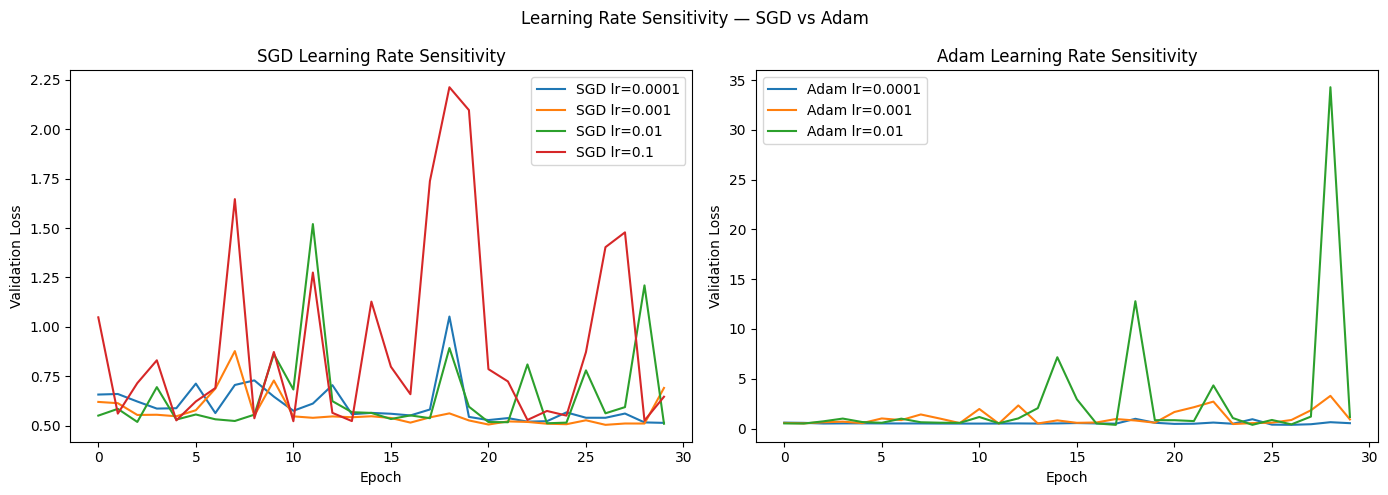

In [ ]:
# Learning Rate Sensitivity — SGD vs Adam

plt.figure(figsize=(14, 5))

# SGD
plt.subplot(1, 2, 1)

for lr, history in sgd_lr_histories.items():

    plt.plot(
        history.history["val_loss"],
        label=f"SGD lr={lr}"
    )

plt.title("SGD Learning Rate Sensitivity")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()


# Adam
plt.subplot(1, 2, 2)

for lr, history in adam_lr_histories.items():

    plt.plot(
        history.history["val_loss"],
        label=f"Adam lr={lr}"
    )

plt.title("Adam Learning Rate Sensitivity")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()


plt.suptitle("Learning Rate Sensitivity — SGD vs Adam")

plt.tight_layout()
plt.show()

### Observation

Adam is generally more robust to learning-rate choice because its adaptive per-parameter learning rates compensate for a suboptimal global learning rate.

SGD can diverge or stall outside a narrower learning-rate window on the Adult dataset's One-Hot Encoded feature space.

The validation-loss curves from this experiment show how different learning rates affect convergence for SGD and Adam.

7.5 Final Combined ANN — Best Configuration

In [ ]:
# Decide whether class weighting improved minority-class F1

use_class_weights = f1_wbce > f1_base

if use_class_weights:
    print("Weighted BCE selected because it improved Class-1 F1.")
    final_class_weight = class_weight_dict
else:
    print("Standard BCE selected because Weighted BCE did not improve Class-1 F1.")
    final_class_weight = None

Standard BCE selected because Weighted BCE did not improve Class-1 F1.


In [ ]:
# Build Final Combined ANN

model_final = built_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer="adam",
    loss="binary_crossentropy"
)

model_final.summary()

Model: "sequential_29"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_87 (Dense)                │ (None, 128)            │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_88 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_89 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,505 (84.00 KB)

 Trainable params: 21,121 (82.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
# Train Final Combined ANN

history_final = model_final.fit(
    X_train,
    y_train,
    epochs=80,
    batch_size=64,
    validation_split=0.1,
    class_weight=final_class_weight,
    verbose=1
)

Epoch 1/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.7746 - loss: 0.5238 - val_accuracy: 0.7888 - val_loss: 0.5097
Epoch 2/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7931 - loss: 0.4991 - val_accuracy: 0.7875 - val_loss: 0.5374
Epoch 3/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7966 - loss: 0.4962 - val_accuracy: 0.7863 - val_loss: 0.5230
Epoch 4/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7953 - loss: 0.4959 - val_accuracy: 0.7913 - val_loss: 0.4988
Epoch 5/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7979 - loss: 0.4927 - val_accuracy: 0.6470 - val_loss: 0.6379
Epoch 6/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7962 - loss: 0.4922 - val_accuracy: 0.5406 - val_loss: 0.6454
Epoch 7/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7936 - loss: 0.4941 - val_accuracy: 0.6498 - val_loss: 0.6156
Epoch 8/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7954 - loss: 0.4915 - val_accuracy: 0.

In [ ]:
# Predict probabilities

y_final_prob = model_final.predict(
    X_test,
    verbose=0
).flatten()

# Convert probabilities to class labels

y_final_pred = (
    y_final_prob >= 0.5
).astype(int)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

final_accuracy = accuracy_score(
    y_test,
    y_final_pred
)

final_precision = precision_score(
    y_test,
    y_final_pred,
    pos_label=1
)

final_recall = recall_score(
    y_test,
    y_final_pred,
    pos_label=1
)

final_f1 = f1_score(
    y_test,
    y_final_pred,
    pos_label=1
)

final_roc_auc = roc_auc_score(
    y_test,
    y_final_prob
)

print("Final Combined ANN — Test Performance")
print("-" * 45)

print(f"Accuracy     : {final_accuracy:.4f}")
print(f"Precision (1): {final_precision:.4f}")
print(f"Recall (1)   : {final_recall:.4f}")
print(f"F1-Score (1) : {final_f1:.4f}")
print(f"ROC-AUC      : {final_roc_auc:.4f}")

Final Combined ANN — Test Performance
---------------------------------------------
Accuracy     : 0.8310
Precision (1): 0.6416
Recall (1)   : 0.7203
F1-Score (1) : 0.6787
ROC-AUC      : 0.8996


### Final Model Configuration

The final ANN combines the strongest configuration identified across the previous experiments:

- Hidden Layers: 128 → 64
- Activation: ReLU
- Weight Initialisation: He Normal
- Batch Normalization: Yes
- Optimizer: Adam
- Loss: Binary Cross-Entropy
- Class Weighting: Used only if Weighted BCE improved class-1 F1
- Training Epochs: 80

The final model is evaluated using Accuracy, Precision, Recall, F1-score for the minority class (`>50K`), and ROC-AUC.

# 7.6 Full Results Comparison Table

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

def evaluate_model(model, X_test, y_test):

    y_prob = model.predict(
        X_test,
        verbose=0
    ).flatten()

    y_pred = (y_prob >= 0.5).astype(int)

    return {
        "Test Acc": accuracy_score(y_test, y_pred),
        "Prec(1)": precision_score(y_test, y_pred, pos_label=1),
        "Recall(1)": recall_score(y_test, y_pred, pos_label=1),
        "F1(1)": f1_score(y_test, y_pred, pos_label=1),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

In [ ]:
# Evaluate required models

results = []

# Baseline
baseline_metrics = evaluate_model(
    model_base,
    X_test,
    y_test
)

results.append({
    "Model": "Baseline",
    "Activation": "ReLU",
    "Init": "Glorot Uniform",
    "Loss": "BCE",
    "BatchNorm": "No",
    "Optimizer": "Adam",
    **baseline_metrics
})


# Best Activation — ReLU
best_activation_metrics = evaluate_model(
    model_relu,
    X_test,
    y_test
)

results.append({
    "Model": "Best Activation",
    "Activation": "ReLU",
    "Init": "Glorot Uniform",
    "Loss": "BCE",
    "BatchNorm": "No",
    "Optimizer": "Adam",
    **best_activation_metrics
})


# Best Initialiser — He Normal
best_init_metrics = evaluate_model(
    model_he_normal,
    X_test,
    y_test
)

results.append({
    "Model": "Best Initialiser",
    "Activation": "ReLU",
    "Init": "He Normal",
    "Loss": "BCE",
    "BatchNorm": "No",
    "Optimizer": "Adam",
    **best_init_metrics
})


# Weighted BCE
wbce_metrics = evaluate_model(
    model_wbce,
    X_test,
    y_test
)

results.append({
    "Model": "Weighted BCE",
    "Activation": "ReLU",
    "Init": "He Normal",
    "Loss": "Weighted BCE",
    "BatchNorm": "No",
    "Optimizer": "Adam",
    **wbce_metrics
})


# Focal Loss
focal_metrics = evaluate_model(
    model_focal,
    X_test,
    y_test
)

results.append({
    "Model": "Focal Loss",
    "Activation": "ReLU",
    "Init": "He Normal",
    "Loss": "Focal Loss",
    "BatchNorm": "No",
    "Optimizer": "Adam",
    **focal_metrics
})


# BatchNorm
bn_metrics = evaluate_model(
    model_bn,
    X_test,
    y_test
)

results.append({
    "Model": "BatchNorm",
    "Activation": "ReLU",
    "Init": "He Normal",
    "Loss": "BCE",
    "BatchNorm": "Yes",
    "Optimizer": "Adam",
    **bn_metrics
})


# Final Combined
final_metrics = evaluate_model(
    model_final,
    X_test,
    y_test
)

results.append({
    "Model": "Final Combined",
    "Activation": "ReLU",
    "Init": "He Normal",
    "Loss": "BCE",
    "BatchNorm": "Yes",
    "Optimizer": "Adam",
    **final_metrics
})

In [ ]:
# Create final results table

results_df = pd.DataFrame(results)

results_df

,Model,Activation,Init,Loss,BatchNorm,Optimizer,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
0,Baseline,ReLU,Glorot Uniform,BCE,No,Adam,0.809287,0.798155,0.308653,0.445159,0.841290
1,Best Activation,ReLU,Glorot Uniform,BCE,No,Adam,0.617800,0.387770,0.936218,0.548400,0.841384
2,Best Initialiser,ReLU,He Normal,BCE,No,Adam,0.792040,0.683996,0.299286,0.416382,0.642648
3,Weighted BCE,ReLU,He Normal,Weighted BCE,No,Adam,0.762631,0.979798,0.043265,0.082871,0.521714
4,Focal Loss,ReLU,He Normal,Focal Loss,No,Adam,0.247319,0.247456,0.997770,0.396561,0.498885
5,BatchNorm,ReLU,He Normal,BCE,Yes,Adam,0.816915,0.715441,0.433988,0.540255,0.812317
6,Final Combined,ReLU,He Normal,BCE,Yes,Adam,0.830956,0.641637,0.720339,0.678714,0.899573


In [ ]:
results_df.style.highlight_max(
    subset=["F1(1)", "ROC-AUC"],
    color="#ffcccc"
)

,Model,Activation,Init,Loss,BatchNorm,Optimizer,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
0,Baseline,ReLU,Glorot Uniform,BCE,No,Adam,0.809287,0.798155,0.308653,0.445159,0.841290
1,Best Activation,ReLU,Glorot Uniform,BCE,No,Adam,0.617800,0.387770,0.936218,0.548400,0.841384
2,Best Initialiser,ReLU,He Normal,BCE,No,Adam,0.792040,0.683996,0.299286,0.416382,0.642648
3,Weighted BCE,ReLU,He Normal,Weighted BCE,No,Adam,0.762631,0.979798,0.043265,0.082871,0.521714
4,Focal Loss,ReLU,He Normal,Focal Loss,No,Adam,0.247319,0.247456,0.997770,0.396561,0.498885
5,BatchNorm,ReLU,He Normal,BCE,Yes,Adam,0.816915,0.715441,0.433988,0.540255,0.812317
6,Final Combined,ReLU,He Normal,BCE,Yes,Adam,0.830956,0.641637,0.720339,0.678714,0.899573


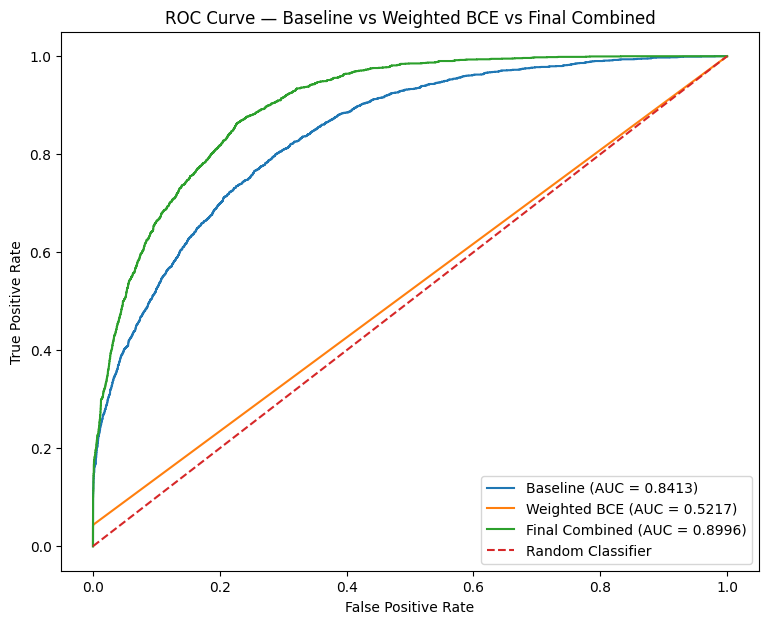

In [ ]:
# ROC Curve comparison

models_for_roc = {
    "Baseline": model_base,
    "Weighted BCE": model_wbce,
    "Final Combined": model_final
}

plt.figure(figsize=(9, 7))

for name, model in models_for_roc.items():

    y_prob = model.predict(
        X_test,
        verbose=0
    ).flatten()

    fpr, tpr, _ = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.4f})"
    )


# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve — Baseline vs Weighted BCE vs Final Combined")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.show()

### Minority-Class F1 Impact

The individual impact of each technique should be evaluated by comparing the Class-1 F1-score across the experiments.

The technique with the largest improvement in minority-class F1 should be identified from the results table.

This comparison helps determine whether the largest improvement came from the activation function, weight initialisation, loss function, Batch Normalization, or optimizer.